## PDAN8412 POE Assignment 03
## Image Recognition with a Convolutional Neural Network (CNN)
Tatenda Amanda Chiza | Student Number: ST10535650

Author's note and code attribution:

I planned and carried out this analysis: I chose and evaluated the dataset, decided on the cleaning steps, image size, model versions and evaluation methods, ran every cell, diagnosed and fixed the errors that came up, checked the labels by eye, and wrote all of the interpretation in the "What this shows" cells.

I used Claude (Anthropic, 2026), an AI assistant, as a coding aid. It helped me draft parts of the code, mainly the
Spark loading cells, the model-building and training cells and the evaluation cells, and helped me troubleshoot errors.
These cells are marked with comments "(Helped by Claude, 2026)". I reviewed, tested and edited this code.

##### What this notebook does
The publisher wants to use facial recognition at its premises. As a first step, this notebook trains a
**Convolutional Neural Network (CNN)** that looks at a face photo and predicts the person's gender.

I used the **UTKFace** dataset (Kaggle): 23,708 face photos, each labelled with age, gender and ethnicity
in its file name. Link: https://www.kaggle.com/datasets/jangedoo/utkface-new

- Spark reads and analyses all the file names and images (EDA).
- TensorFlow/Keras builds and trains the CNN.
- scikit-learn calculates the scores.

#### Step 0: Set-up and Loading the Data

In [1]:
# Set up the environment so Spark can find Java and uses this notebook's Python

import os, sys, shutil

java_exe = shutil.which("java")      # Find where Java is installed, instead of typing a fixed path
os.environ["JAVA_HOME"] = os.path.dirname(os.path.dirname(os.path.realpath(java_exe)))
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"      # "127.0.0.1" means this computer, so no network is needed

# Tell Spark's helper programs ("workers") to use the same Python as this notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Print both settings, to check they are correct before going on
print("Python:", sys.executable)
print("JAVA_HOME:", os.environ["JAVA_HOME"])

Python: c:\tools\Anaconda3\envs\py311\python.exe
JAVA_HOME: C:\Program Files\Eclipse Adoptium\jdk-11.0.32.101-hotspot


In [ ]:
# Start a local Spark session for the analysis # Helped by Claude, 2026
from pyspark import SparkContext
from pyspark.sql import SparkSession

# Stop any half-started session left over from an earlier run
if SparkContext._active_spark_context is not None:
    SparkContext._active_spark_context.stop()

spark = (
    SparkSession.builder
    .appName("UTKFaceCNN")                            # A name for this job
    .master("local[2]")                               # Run on this computer, using 2 processor cores
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.memory", "4g")              # More memory, because Spark will read image files
    .config("spark.ui.enabled", "false")              # Turn off Spark's web dashboard (not needed)
    .config("spark.ui.showConsoleProgress", "false")  # Hide progress bars so outputs stay readable
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")               # Only print real errors
spark.conf.set("spark.sql.shuffle.partitions", "8")   # Fewer pieces for one computer (the default of 200 is too many)

print("Spark version:", spark.version)

Spark version: 3.5.8


In [ ]:
# List the image files with Python, then load the list into Spark and pull the labels out of each file name. # Helped by Claude, 2026

import os
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, StringType, LongType

IMAGE_DIR = "UTKFace"

# On Windows, Spark needs extra Hadoop files (winutils) to list a folder, and this VM does not have them.
# So Python lists the folder instead: os.scandir goes through every file once and gives its name and size.
rows = [(e.name, os.path.abspath(e.path), e.stat().st_size)
        for e in os.scandir(IMAGE_DIR)
        if e.is_file() and e.name.lower().endswith(".jpg")]

# Hand the list to Spark. From here on, all the analysis is done in Spark.
schema = StructType([StructField("filename", StringType()),     # e.g. 25_1_2_20170116174525125.jpg.chip.jpg
                     StructField("path", StringType()),         # full location of the file on this computer
                     StructField("length", LongType())])        # file size in bytes
files = spark.createDataFrame(rows, schema)

# UTKFace file names follow the pattern  age_gender_ethnicity_date.jpg
#   gender:    0 = male, 1 = female
#   ethnicity: 0 = White, 1 = Black, 2 = Asian, 3 = Indian, 4 = Others
# regexp_extract pulls out each part. If a file name breaks the pattern, it returns "",
# which cast("int") turns into an empty value (null), so broken names are easy to find later.
pattern = r"^(\d+)_(\d+)_(\d+)_(\d+)"
images = (files
    .withColumn("age",       F.regexp_extract("filename", pattern, 1).cast("int"))
    .withColumn("gender",    F.regexp_extract("filename", pattern, 2).cast("int"))
    .withColumn("ethnicity", F.regexp_extract("filename", pattern, 3).cast("int")))

images.cache()      # keep the table in memory, because it will be used many times in the EDA

# How many images, and what do the first rows look like?
print("Images found:", images.count())
images.select("filename", "age", "gender", "ethnicity", "length").show(5, truncate=45)

Images found: 23708
+--------------------------------------+---+------+---------+------+
|                              filename|age|gender|ethnicity|length|
+--------------------------------------+---+------+---------+------+
|100_0_0_20170112213500903.jpg.chip.jpg|100|     0|        0|  7916|
|100_0_0_20170112215240346.jpg.chip.jpg|100|     0|        0|  7208|
|100_1_0_20170110183726390.jpg.chip.jpg|100|     1|        0|  9018|
|100_1_0_20170112213001988.jpg.chip.jpg|100|     1|        0|  7184|
|100_1_0_20170112213303693.jpg.chip.jpg|100|     1|        0|  7631|
+--------------------------------------+---+------+---------+------+
only showing top 5 rows



In [4]:
# Check that TensorFlow and Keras work in this notebook before building any CNN
import numpy as np
import tensorflow as tf
import keras

# A tiny test network: 4 numbers in, 1 number out. If it runs, Keras and TensorFlow work together.
test_model = keras.Sequential([keras.Input((4,)), keras.layers.Dense(1)])
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Test output shape:", test_model.predict(np.zeros((2, 4)), verbose=0).shape)   # should be (2, 1)

TensorFlow: 2.17.1 | Keras: 3.15.1
Test output shape: (2, 1)


#### STEP 1: Exploratory Data Analysis (Spark)

##### 1.1 Data Quality Checks
Before training, the labels are checked for problems:
- broken file names, where a label could not be read (empty value);
- impossible values, such as a gender other than 0/1, an ethnicity outside 0 - 4, or an impossible age;
- suspicious files, such as files that are unusually small (possibly blank or damaged images).

In [5]:
# Data quality checks on the labels and file sizes (all in Spark)

# 1) Broken file names: if the name did not match the pattern, the label is empty (null)
broken = images.filter(F.col("age").isNull() | F.col("gender").isNull() | F.col("ethnicity").isNull())
print("Broken file names (a label could not be read):", broken.count())
broken.select("filename").show(truncate=False)

# 2) Impossible label values
print("Gender not 0 or 1:      ", images.filter(~F.col("gender").isin(0, 1)).count())
print("Ethnicity not 0 to 4:   ", images.filter(~F.col("ethnicity").isin(0, 1, 2, 3, 4)).count())
print("Age below 1 or above 116:", images.filter((F.col("age") < 1) | (F.col("age") > 116)).count())

# 3) Range of ages and file sizes: min, quarter points, median (50%), max and average
images.select("age", "length").summary("min", "25%", "50%", "75%", "max", "mean").show()

# 4) Unusually small files may be blank or damaged images. Count files under 2 KB
print("Files smaller than 2 KB:", images.filter(F.col("length") < 2000).count())

Broken file names (a label could not be read): 3
+-----------------------------------+
|filename                           |
+-----------------------------------+
|39_1_20170116174525125.jpg.chip.jpg|
|61_1_20170109142408075.jpg.chip.jpg|
|61_1_20170109150557335.jpg.chip.jpg|
+-----------------------------------+

Gender not 0 or 1:       0
Ethnicity not 0 to 4:    0
Age below 1 or above 116: 0
+-------+-----------------+-----------------+
|summary|              age|           length|
+-------+-----------------+-----------------+
|    min|                1|             2060|
|    25%|               23|             4508|
|    50%|               29|             4972|
|    75%|               45|             5495|
|    max|              116|            12025|
|   mean|33.30090698164944|5061.003754007086|
+-------+-----------------+-----------------+

Files smaller than 2 KB: 0


What this shows:
- 3 broken file names (e.g. `39_1_20170116174525125.jpg.chip.jpg`). Each is missing the ethnicity number so its labels cannot be fully read. 
Decision: remove these 3 images (0.01% of the data).

- No impossible values: every gender is 0 or 1, every ethnicity is 0 - 4, and every age is between 1 and 116.
- File sizes range from about 2 KB to 12 KB (median 4.9 KB), and no file is under 2 KB, so there are no obviously empty or damaged images. Image content is checked further in 1.6.
- Ages: the median age is 29, and half of all people are between 23 and 45.

##### 1.2 Class Balance: Gender
How many photos are male and how many are female? If one class is much bigger, the model can look accurate just by guessing the bigger class.

     label  count  percent
  Male (0)  12391    52.27
Female (1)  11314    47.73


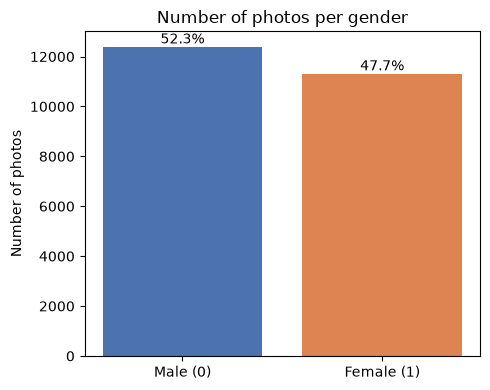

In [6]:
# How balanced are the two classes the model must predict?
import matplotlib.pyplot as plt

# Keep only the images whose labels could be read
clean = images.dropna(subset=["age", "gender", "ethnicity"])

# Spark counts each gender; the result is only 2 rows, so it is safe to move to pandas for the chart
gender_counts = (clean.groupBy("gender").count().orderBy("gender").toPandas())
gender_counts["label"] = gender_counts["gender"].map({0: "Male (0)", 1: "Female (1)"})
gender_counts["percent"] = gender_counts["count"] / gender_counts["count"].sum() * 100
print(gender_counts[["label", "count", "percent"]].round(2).to_string(index=False))

plt.figure(figsize=(5, 4))
bars = plt.bar(gender_counts["label"], gender_counts["count"], color=["#4C72B0", "#DD8452"])
for b, p in zip(bars, gender_counts["percent"]):
    plt.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{p:.1f}%", ha="center", va="bottom")
plt.title("Number of photos per gender"); plt.ylabel("Number of photos")
plt.tight_layout(); plt.show()

What this shows: 

The two classes are nearly balanced: 12,391 male photos (52.3%) and 11,314 female photos (47.7%).
A model that always guessed "male" would be right only 52.3% of the time, so, unlike Part 2, accuracy is a fair score here.
F1 and ROC-AUC are still reported, to see both classes clearly.

Decision: no class weights are needed, but the split will be stratified so every part keeps the same balance.

##### 1.3 Age: Distribution and Age Groups
What ages are in the data, and is the male/female balance the same at every age? Ages are also grouped,
so later the model's accuracy can be checked separately for each age group.

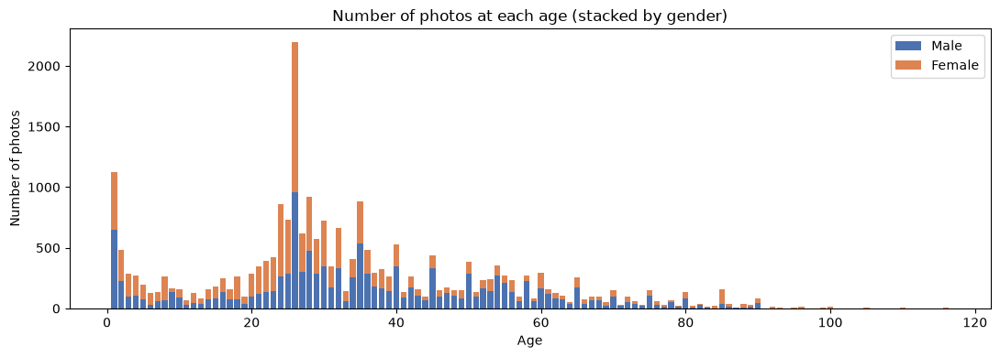

+----------------------+------+-------+--------+
|age_group             |photos|share_%|female_%|
+----------------------+------+-------+--------+
|1. Baby (0-2)         |1605  |6.8    |45.6    |
|2. Child (3-12)       |1808  |7.6    |59.4    |
|3. Teen (13-19)       |1180  |5.0    |55.8    |
|4. Young adult (20-39)|11880 |50.1   |53.4    |
|5. Adult (40-59)      |4544  |19.2   |30.1    |
|6. Senior (60+)       |2688  |11.3   |42.5    |
+----------------------+------+-------+--------+



In [7]:
# Age distribution, split by gender
# Spark counts photos for each age and gender (about 200 rows), then pandas draws the chart
age_counts = clean.groupBy("age", "gender").count().toPandas()
pivot = age_counts.pivot(index="age", columns="gender", values="count").fillna(0)

plt.figure(figsize=(11, 4))
plt.bar(pivot.index, pivot.get(0, 0), label="Male", color="#4C72B0")
plt.bar(pivot.index, pivot.get(1, 0), bottom=pivot.get(0, 0), label="Female", color="#DD8452")
plt.title("Number of photos at each age (stacked by gender)")
plt.xlabel("Age"); plt.ylabel("Number of photos"); plt.legend()
plt.tight_layout(); plt.show()

# Age groups: put each person into a life stage
# F.when works like "if... else if... otherwise"
clean = clean.withColumn("age_group",
    F.when(F.col("age") <= 2,  "1. Baby (0-2)")
     .when(F.col("age") <= 12, "2. Child (3-12)")
     .when(F.col("age") <= 19, "3. Teen (13-19)")
     .when(F.col("age") <= 39, "4. Young adult (20-39)")
     .when(F.col("age") <= 59, "5. Adult (40-59)")
     .otherwise("6. Senior (60+)"))

# For each age group: number of photos, and the share that are female
(clean.groupBy("age_group")
      .agg(F.count("*").alias("photos"),
           F.round(F.count("*") / clean.count() * 100, 1).alias("share_%"),
           F.round(F.avg("gender") * 100, 1).alias("female_%"))    # average of 0/1 = share of 1s (female)
      .orderBy("age_group").show(truncate=False))

What this shows:
- Most photos are of young adults: half (50.1%) are aged 20 - 39. Teens are the smallest group (5.0%).
- Gender balance changes with age: only 30.1% of adults aged 40 - 59 are female, but 59.4% of children aged 3 - 12 are. So the model could learn "looks older = probably male" instead of real gender features. Decision: check accuracy separately for each age group in the evaluation.

- Two odd spikes: about 2,200 photos are labelled age 26 and about 1,100 age 1, far more than nearby ages. There are also smaller spikes at round numbers (30, 35, 40, 45…). This pattern is called age heaping. It happens when ages are estimated and rounded rather than known, which suggests some age labels are guesses. This is tested below.
- Babies (0 - 2) are 6.8% of the data. Gender is very hard to see in a baby's face, even for people, so this group is likely to be the hardest for the model.

##### 1.4 Ethnicity
How many photos are there of each ethnic group? If some groups are small, the model may learn them less well. This is a known problem in face recognition, so it is checked here and again when the model is evaluated.

  name  photos  share_%  female_%
 White   10078     42.5      45.7
 Black    4526     19.1      48.8
 Asian    3434     14.5      54.1
Indian    3975     16.8      43.1
Others    1692      7.1      55.1


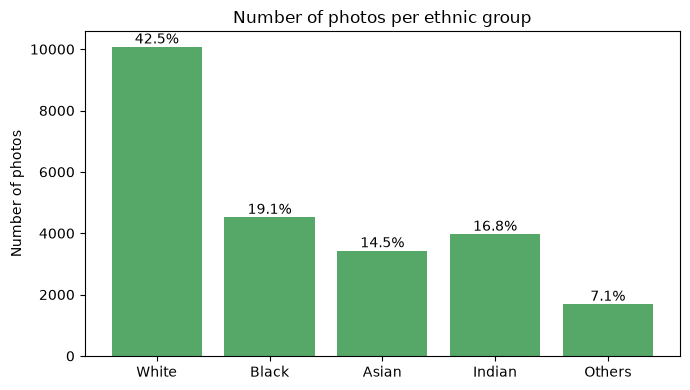

In [8]:
# Number of photos and share female for each ethnic group
ethnicity_names = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Others"}
eth = (clean.groupBy("ethnicity")
            .agg(F.count("*").alias("photos"),
                 F.round(F.avg("gender") * 100, 1).alias("female_%"))
            .orderBy("ethnicity").toPandas())
eth["name"] = eth["ethnicity"].map(ethnicity_names)
eth["share_%"] = (eth["photos"] / eth["photos"].sum() * 100).round(1)
print(eth[["name", "photos", "share_%", "female_%"]].to_string(index=False))

plt.figure(figsize=(7, 4))
bars = plt.bar(eth["name"], eth["photos"], color="#55A868")
for b, s in zip(bars, eth["share_%"]):
    plt.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{s}%", ha="center", va="bottom")
plt.title("Number of photos per ethnic group"); plt.ylabel("Number of photos")
plt.tight_layout(); plt.show()

What this shows:

The groups are unbalanced. White faces are 42.5% of the photos, while Black (19.1%), Indian (16.8%),
Asian (14.5%) and especially "Others" (7.1%) are smaller. The female share also differs, from 43.1% (Indian) to 55.1% (Others).

A model learns most from the groups it sees most, so it may be less accurate on smaller groups. Research on commercial face systems found exactly this kind of unequal accuracy. *Decision:* report accuracy for each ethnic group, not just overall. The labels are also very broad: "Others" mixes many backgrounds, which is a limitation of the dataset.

##### 1.5 Is Gender Linked to Age Group or Ethnicity? (Chi-squared tests)
A chi-squared test checks whether two labels are linked. It compares the real counts with the counts we would expect if there were no link. A **p-value** below 0.05 means the link is very unlikely to be chance. If gender is linked to age group, the model could learn "age clues" instead of "gender clues".

In [9]:
# Chi-squared tests: is gender linked to age group, and to ethnicity?
from scipy.stats import chi2_contingency

for col in ["age_group", "ethnicity"]:
    # Spark builds the table of counts (e.g. age group x gender); it is small, so it moves to pandas
    table = clean.groupBy(col).pivot("gender", [0, 1]).count().orderBy(col).toPandas().set_index(col).fillna(0)
    table.columns = ["male", "female"]
    chi2, p, dof, _ = chi2_contingency(table)    # compares real counts with "no link" counts
    print(f"\nGender vs {col}:")
    print(table.to_string())
    print(f"Chi-squared = {chi2:.1f}, degrees of freedom = {dof}, p-value = {p:.3g}")


Gender vs age_group:
                        male  female
age_group                           
1. Baby (0-2)            873     732
2. Child (3-12)          734    1074
3. Teen (13-19)          521     659
4. Young adult (20-39)  5539    6341
5. Adult (40-59)        3178    1366
6. Senior (60+)         1546    1142
Chi-squared = 882.8, degrees of freedom = 5, p-value = 1.42e-188

Gender vs ethnicity:
           male  female
ethnicity              
0          5477    4601
1          2318    2208
2          1575    1859
3          2261    1714
4           760     932
Chi-squared = 146.4, degrees of freedom = 4, p-value = 1.18e-30


What this shows:

Both tests give p-values far below 0.05:
- Gender vs age group: chi-squared = 882.8, p = 1.4 × 10⁻¹⁸⁸
- Gender vs ethnicity: chi-squared = 146.4, p = 1.2 × 10⁻³⁰

So gender is not independent of age or ethnicity in this dataset. The strongest imbalance is in adults aged 40 - 59 (3,178 male vs 1,366 female).
Decision: the model's mistakes must be checked by age group and ethnicity, because it may partly learn these patterns instead of gender itself. This is the basis of the fairness evaluation.

##### 1.6 Are the Ages Estimated? (Age Heaping Check)
If ages were known exactly, about 1 in 5 adults (20%) should have an age ending in 0 or 5. If many more do, the ages were probably estimated and rounded, which means the labels are less exact.

In [10]:
# Age heaping: what share of adults (20-80) have an age ending in 0 or 5?
# If ages were exact, it should be about 20% (2 out of every 10 possible last digits)
adults = clean.filter((F.col("age") >= 20) & (F.col("age") <= 80))
heaped = adults.filter(F.col("age") % 5 == 0).count()
print(f"Adults aged 20-80: {adults.count()} | ages ending in 0 or 5: {heaped} "
      f"({heaped / adults.count():.1%}, expected about 20%)")

# The 10 most common ages, to show the spikes
clean.groupBy("age").count().orderBy(F.desc("count")).show(10)

Adults aged 20-80: 18572 | ages ending in 0 or 5: 5217 (28.1%, expected about 20%)
+---+-----+
|age|count|
+---+-----+
| 26| 2197|
|  1| 1123|
| 28|  918|
| 35|  880|
| 24|  859|
| 25|  734|
| 30|  724|
| 32|  664|
| 27|  615|
| 29|  570|
+---+-----+
only showing top 10 rows



What this shows:

28.1% of adults aged 20 - 80 have an age ending in 0 or 5, compared with about 20% expected if ages were exact. Ages 26 (2,197 photos) and 1 (1,123 photos) are also far more common than the ages around them. This is clear age heaping: many ages were estimated and rounded by the people who labelled the photos.

Decision: age is not the target, so this does not affect training directly. But age groups are used to check fairness, so they are kept wide (e.g. 20 - 39), because a guess of 26 for someone who is 24 still falls in the right group. It is also a warning that other labels may contain mistakes, which is tested in 1.8.

##### 1.7 Looking Inside the Images (Spark)
The file names are clean, but what about the pictures themselves? Spark opens every image and measures:
- width and height: a CNN needs every image to be the same size;
- colour mode: colour (RGB) or black-and-white;
- brightness: the average pixel value, from 0 (black) to 255 (white); very dark or very bright faces are harder to read;
- contrast: how much the pixel values vary; low contrast means a flat, washed-out picture;
- sharpness: how strong the edges are; a low value means a blurry photo;
- fingerprint (MD5 hash): a code made from the file's exact bytes. Two files with the same code are exact duplicates.

In [11]:
# Open every image inside Spark and measure its size, colour mode, brightness, contrast, sharpness and fingerprint
# (Helped by Claude, 2026)
import hashlib
from PIL import Image, ImageFilter, ImageStat
from pyspark.sql.types import IntegerType, DoubleType

stats_schema = StructType([
    StructField("width", IntegerType()), StructField("height", IntegerType()),
    StructField("mode", StringType()),
    StructField("brightness", DoubleType()), StructField("contrast", DoubleType()),
    StructField("sharpness", DoubleType()), StructField("md5", StringType())])

@F.udf(returnType=stats_schema)        # a UDF lets Spark run this Python function on every row
def image_stats(path):
    with open(path, "rb") as f:
        data = f.read()
    md5 = hashlib.md5(data).hexdigest()               # fingerprint of the exact file bytes
    with Image.open(path) as img:
        w, h, mode = img.width, img.height, img.mode
        grey = img.convert("L")                        # black-and-white copy, for brightness, contrast and edges
        st = ImageStat.Stat(grey)
        brightness = st.mean[0]                        # average pixel value (0 = black, 255 = white)
        contrast = st.stddev[0]                        # spread of pixel values
        edges = grey.filter(ImageFilter.FIND_EDGES)    # highlights edges; blurry photos have weak edges
        sharpness = ImageStat.Stat(edges).var[0]       # variance of the edge image = sharpness score
    return (w, h, mode, float(brightness), float(contrast), float(sharpness), md5)

# Run it on every image. This opens 23,705 files, so it can take a few minutes.
img_stats = clean.withColumn("s", image_stats("path")).select("*", "s.*").drop("s").cache()
print("Images measured:", img_stats.count())

# Image sizes and colour modes
img_stats.groupBy("width", "height").count().orderBy(F.desc("count")).show(5)
img_stats.groupBy("mode").count().show()

# Brightness, contrast and sharpness: min, quarter points, median, max and average
img_stats.select("brightness", "contrast", "sharpness").summary("min", "1%", "25%", "50%", "75%", "max", "mean").show()

Images measured: 23705
+-----+------+-----+
|width|height|count|
+-----+------+-----+
|  200|   200|23705|
+-----+------+-----+

+----+-----+
|mode|count|
+----+-----+
| RGB|23705|
+----+-----+

+-------+------------------+------------------+------------------+
|summary|        brightness|          contrast|         sharpness|
+-------+------------------+------------------+------------------+
|    min|           25.8082|12.659691877668271|     14.5415239975|
|     1%|          59.79915| 25.10457336272368|   93.593266224375|
|    25%|        105.317175| 41.18278620673936|  278.926265234375|
|    50%|        124.476075|49.439421869337984|  409.285690969375|
|    75%|        144.379475| 58.56671357775998|    592.4330950975|
|    max|        239.394625| 104.8879176532949| 5369.473090419375|
|   mean|125.12654553997054| 50.32659336255839|461.75177268523424|
+-------+------------------+------------------+------------------+



What this shows:
- Every image is 200 × 200 pixels and stored in RGB colour. A CNN needs every input to be the same size, so no cropping or padding is needed, only resizing to a smaller size to make training faster on a CPU.
- Brightness ranges from 25.8 (very dark) to 239.4 (very bright), with a median of 124.5 out of 255. The darkest 1% are below 60.
- Contrast (median 49.4) and sharpness (median 409) vary a lot. The blurriest 1% have a sharpness below 94 less than a quarter of the median.
- The sample faces show that some photos are black-and-white pictures saved as RGB, so "RGB" does not always mean colour.This is checked in 1.10.

Decision: pixel values will be rescaled from 0 - 255 to 0 - 1 before training, because neural networks learn faster with small, similar-sized numbers Poor-quality photos are kept, because the client's cameras will also capture imperfect faces.

##### 1.8 Duplicate and Poor-Quality Images
Duplicate photos are dangerous: if the same face is in both the training and test sets, the model is tested on a photo it has already seen, and the score looks better than it really is (data leakage). Very dark, flat or blurry photos are also checked, to see whether they are linked to any group.

In [12]:
# 1) Exact duplicates: images that share the same fingerprint (MD5)
dups = img_stats.groupBy("md5").agg(F.count("*").alias("copies"),
                                    F.collect_list("filename").alias("files")).filter("copies > 1")
print("Groups of exact duplicate images:", dups.count())
print("Extra copies to remove:", dups.agg(F.sum(F.col("copies") - 1)).first()[0] or 0)
dups.show(5, truncate=80)

# 2) Duplicates with DIFFERENT labels (same photo, different gender), which would be a labelling error
dup_conflicts = (img_stats.join(dups.select("md5"), "md5")
                          .groupBy("md5").agg(F.countDistinct("gender").alias("genders"))
                          .filter("genders > 1"))
print("Duplicate groups with conflicting gender labels:", dup_conflicts.count())

# 3) Poor-quality images: the darkest, flattest and blurriest 1% of photos
q = img_stats.approxQuantile(["brightness", "contrast", "sharpness"], [0.01], 0.001)
dark_cut, flat_cut, blur_cut = q[0][0], q[1][0], q[2][0]
print(f"Bottom 1% cut-offs -> brightness < {dark_cut:.1f}, contrast < {flat_cut:.1f}, sharpness < {blur_cut:.1f}")

# 4) Average image quality per ethnic group: are some groups photographed in darker or blurrier conditions?
(img_stats.groupBy("ethnicity")
          .agg(F.count("*").alias("photos"),
               F.round(F.avg("brightness"), 1).alias("avg_brightness"),
               F.round(F.avg("contrast"), 1).alias("avg_contrast"),
               F.round(F.avg("sharpness"), 1).alias("avg_sharpness"))
          .orderBy("ethnicity").show())

Groups of exact duplicate images: 375
Extra copies to remove: 390
+--------------------------------+------+------------------------------------------------------------------------------+
|                             md5|copies|                                                                         files|
+--------------------------------+------+------------------------------------------------------------------------------+
|009fa4c83098f3da81209b5d964947e6|     2|[21_0_2_20170103234754659.jpg.chip.jpg, 21_0_2_20170117193634310.jpg.chip.jpg]|
|01576199681aca21affcce48f81964a3|     2|[58_0_3_20170119211656985.jpg.chip.jpg, 58_0_3_20170119211703657.jpg.chip.jpg]|
|03a2405ef52f6839ea2d6af160b83de7|     2|[24_1_0_20170105162704533.jpg.chip.jpg, 31_1_0_20170105162708403.jpg.chip.jpg]|
|046bbaaa73e9f0323624704b2dda38ae|     2|[16_0_0_20170110231219975.jpg.chip.jpg, 16_0_0_20170110231617005.jpg.chip.jpg]|
|04b0c53dbcaffaef6676254251fb6bab|     2|[33_0_1_20170117173931669.jpg.chip.jpg, 33_1_1

What this shows:
- 375 groups of exact duplicate images (390 extra copies). If one copy ended up in training and another in testing, the model would be tested on a photo it has already seen, and its score would look better than it really is (data leakage).
- 40 duplicate groups have conflicting gender labels: the exact same photo is labelled male in one file and female in another (e.g. `33_0_1_...` and `33_1_1_...`). Other duplicates have different ages (e.g. the same photo labelled 24 and 31). This proves the dataset contains label noise: some labels are simply wrong.
- Image quality differs by ethnic group. Photos of Black faces are darker on average (brightness 104.0 vs 132.3 for White), and all non-White groups have lower average sharpness (414.8 - 473.2 vs 501.3). Brightness reflects both skin tone and lighting, which cannot be separated here, but either way the model receives less contrast and detail for some groups.

Decisions:
1. For the 40 groups with conflicting labels, remove every copy, because the correct label is unknown.
2. For the other duplicate groups, keep one copy, so no photo can appear in both training and testing.
3. Check accuracy separately for each ethnic group, to see whether the darker and less sharp photos lead to more mistakes.

##### 1.9 Sample Faces
A look at real examples from each age group and gender, to see what the model will be learning from.

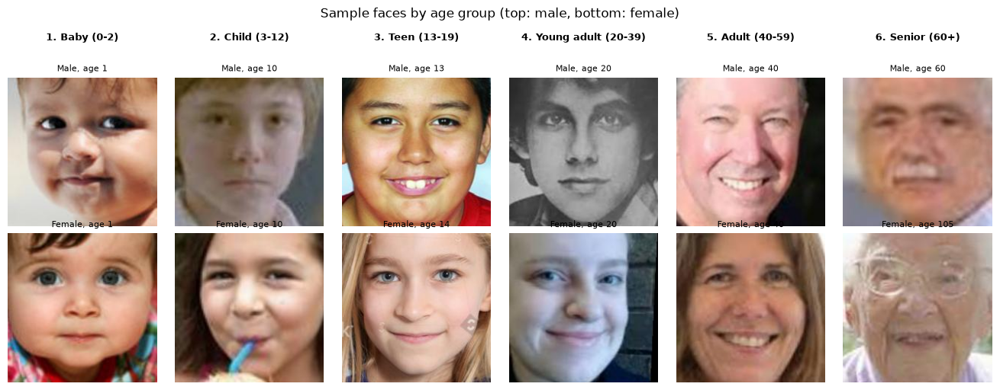

In [13]:
# Show 2 random faces (1 male, 1 female) from each age group
samples = (img_stats.select("path", "gender", "age", "age_group")
                    .sample(fraction=0.05, seed=42).toPandas())     # a small random sample, safe to move to pandas
groups = sorted(samples["age_group"].unique())

fig, axes = plt.subplots(2, len(groups), figsize=(2.2 * len(groups), 5))
for col, grp in enumerate(groups):
    for row, g in enumerate([0, 1]):                        # row 0 = male, row 1 = female
        pick = samples[(samples["age_group"] == grp) & (samples["gender"] == g)].head(1)
        ax = axes[row, col]
        if len(pick):
            ax.imshow(Image.open(pick["path"].iloc[0]))
            ax.set_title(f"{'Male' if g == 0 else 'Female'}, age {pick['age'].iloc[0]}", fontsize=8)
        ax.axis("off")
    axes[0, col].text(0.5, 1.25, grp, transform=axes[0, col].transAxes, ha="center", fontsize=9, weight="bold")
plt.suptitle("Sample faces by age group (top: male, bottom: female)", y=1.02)
plt.tight_layout(); plt.show()

What this shows:

The faces are cropped and centred, so the CNN can focus on the face rather than the background.
They also vary a lot in lighting, pose, expression, glasses, image quality and photo age: some are old black-and-white photos, and some are blurry. Babies' faces look very similar for both genders, which supports the expectation that babies will be the hardest group to classify.

Decision: use data augmentation in v2 (small random flips, rotations, zooms and brightness changes), so the model learns to cope with this kind of variety instead of memorising specific photos.

##### 1.10 How Many Photos Are Really Black-and-White?
All files are stored as RGB, but some are old black-and-white photos. In a true black-and-white photo the red, green and blue values of each pixel are almost the same. A colourfulness score measures the average difference between the three colours:
close to 0 means black-and-white.

In [14]:
# Colourfulness: average difference between the red, green and blue values of each pixel
# (close to 0 = black-and-white photo saved as RGB)
from PIL import ImageChops

@F.udf(returnType=DoubleType())
def colourfulness(path):
    with Image.open(path) as img:
        r, g, b = img.convert("RGB").split()            # separate the red, green and blue layers
        rg = ImageStat.Stat(ImageChops.difference(r, g)).mean[0]   # average red-green difference
        gb = ImageStat.Stat(ImageChops.difference(g, b)).mean[0]   # average green-blue difference
    return float((rg + gb) / 2)

img_stats = img_stats.withColumn("colourfulness", colourfulness("path")).cache()
bw = img_stats.filter(F.col("colourfulness") < 2)       # less than 2 out of 255 = effectively black-and-white
print("Black-and-white photos (colourfulness < 2):", bw.count(),
      f"({bw.count() / img_stats.count():.1%} of all photos)")

# Are black-and-white photos more common in some age groups? (e.g. old photos of older people)
(img_stats.groupBy("age_group")
          .agg(F.round(F.avg((F.col("colourfulness") < 2).cast("int")) * 100, 1).alias("black_and_white_%"))
          .orderBy("age_group").show(truncate=False))

Black-and-white photos (colourfulness < 2): 696 (2.9% of all photos)
+----------------------+-----------------+
|age_group             |black_and_white_%|
+----------------------+-----------------+
|1. Baby (0-2)         |0.6              |
|2. Child (3-12)       |1.3              |
|3. Teen (13-19)       |3.7              |
|4. Young adult (20-39)|3.3              |
|5. Adult (40-59)      |3.2              |
|6. Senior (60+)       |2.8              |
+----------------------+-----------------+



What this shows:

696 photos (2.9%) are really black-and-white, even though they are saved as RGB. They are least common
among babies (0.6%) and most common among teens (3.7%) and young adults (3.3%), probably because older scanned photos were collected for those ages.

Decision: keep the images in colour (RGB). 97% of the photos have real colour, and colour carries useful information such as hair and skin tone. Pre-trained models (used in v3) also expect three colour layers. The black-and-white photos are kept too, because real cameras may also produce black-and-white or washed-out images.

##### 1.11 Building the Clean Dataset
The cleaning decisions from the EDA are applied here, in Spark, before any data is split:
1. Remove the 3 images with broken file names (already done when `clean` was created).
2. Remove all copies of the 40 duplicate photos with conflicting gender labels.
3. Keep one copy of every other duplicate photo.

In [15]:
# Apply the cleaning decisions in Spark
from pyspark.sql.window import Window

# 1) The fingerprints (md5) of duplicate groups whose copies disagree on gender
conflict_md5 = dup_conflicts.select("md5")

# 2) "left_anti" keeps only the rows whose md5 is NOT in the conflict list, so all conflicting copies are removed
no_conflicts = img_stats.join(conflict_md5, "md5", "left_anti")

# 3) For the remaining duplicates, number the copies in each md5 group (1, 2, 3...) and keep only copy number 1
w = Window.partitionBy("md5").orderBy("filename")
final = (no_conflicts.withColumn("copy_no", F.row_number().over(w))
                     .filter("copy_no = 1").drop("copy_no").cache())

print("Before cleaning:", images.count())
print("After cleaning: ", final.count())
print("Removed:        ", images.count() - final.count())

# Check that the gender balance is still the same after cleaning
(final.groupBy("gender").count()
      .withColumn("percent", F.round(F.col("count") / final.count() * 100, 2))
      .orderBy("gender").show())

Before cleaning: 23708
After cleaning:  23275
Removed:         433
+------+-----+-------+
|gender|count|percent|
+------+-----+-------+
|     0|12155|  52.22|
|     1|11120|  47.78|
+------+-----+-------+



What this shows:

Cleaning removed 433 images (1.8%): the 3 broken file names, every copy of the 40 duplicate photos with conflicting gender labels, and the extra copies of the other duplicates. 23,275 images remain, and the
gender balance is unchanged (52.2% male, 47.8% female), so cleaning did not create a new imbalance.

##### 1.12 EDA Summary: How Each Finding Shapes the Model

| Finding | Decision |
|---|---|
| 3 broken file names | Removed |
| 390 exact duplicate copies, including 40 with conflicting gender labels | Conflicting copies removed, one copy kept of the rest, **before** splitting (prevents leakage) |
| Gender is nearly balanced (52/48) | Accuracy is a fair score; F1 and ROC-AUC also reported; stratified split |
| Gender is linked to age group (p = 1.4 × 10⁻¹⁸⁸) and ethnicity (p = 1.2 × 10⁻³⁰) | Accuracy checked separately for each age group and ethnicity (fairness evaluation) |
| White faces are 42.5% of photos, "Others" only 7.1% | Split stratified by gender **and** ethnicity, so every group appears in every part |
| Ages are heaped at 26, 1 and round numbers | Ages used only in wide groups for evaluation, not as a target |
| All images are 200 × 200 RGB; 2.9% are black-and-white | Resize to a smaller size for CPU training; keep 3 colour layers |
| Brightness, contrast and sharpness vary, and are lower for some groups | Rescale pixels to 0 - 1; data augmentation (brightness, flips, zoom) in v2 |
| Babies' faces look similar for both genders | Expect babies to be the hardest group, and check this in the evaluation |

#### STEP 2: Feature Selection and Data Preparation

In a table of data, feature selection means choosing which columns to keep, for example with p-values.
A CNN is different: its input is the raw pixels, and its convolution layers learn their own features, such as edges, then shapes like eyes and lips, then whole faces. So p-value elimination does not apply to pixels. Instead, feature selection here means choosing what the model sees:
- Image size: smaller images train much faster, but too small loses detail.
- Colour: RGB (3 layers) or black-and-white (1 layer). Colour was chosen in 1.10.
- Pixel scale: values are rescaled from 0 - 255 to 0 - 1.

The chi-squared tests in 1.5 are the p-value evidence. They showed which labels are linked to gender, and
these links are checked again in the evaluation.

##### 2.1 Choosing the Image Size
The same face is shown at four sizes, to find the smallest size that still keeps the features needed to tell gender apart.

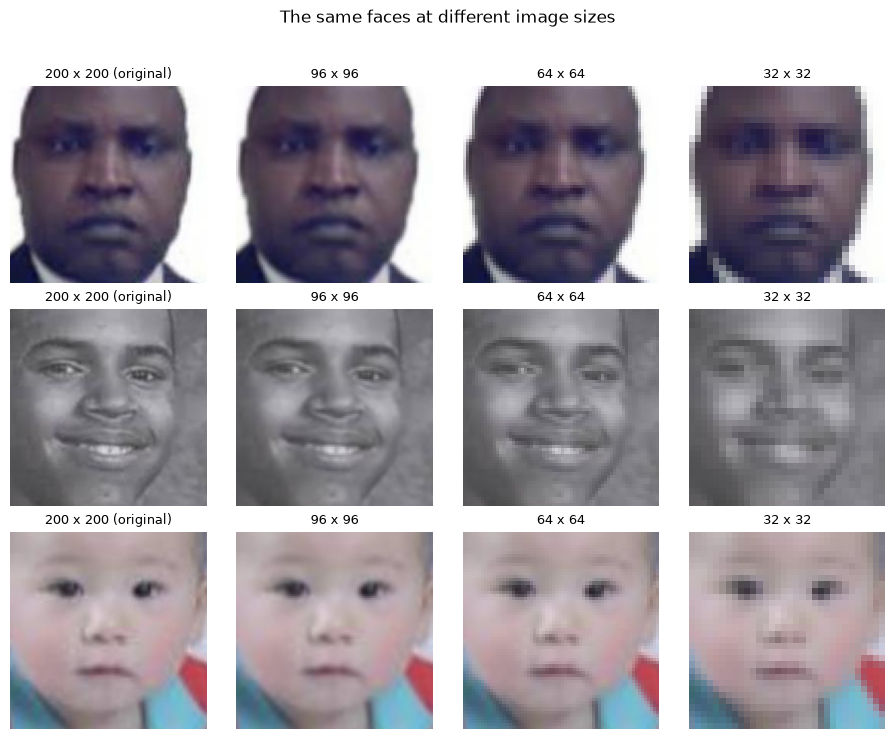

200 x 200: 2,793 MB
96 x 96: 644 MB
64 x 64: 286 MB
32 x 32: 72 MB


In [16]:
# Show the same faces at four sizes, to choose the smallest size that keeps enough detail
sizes = [200, 96, 64, 32]
examples = final.select("path", "gender", "age").sample(fraction=0.001, seed=7).limit(3).toPandas()

fig, axes = plt.subplots(len(examples), len(sizes), figsize=(2.3 * len(sizes), 2.4 * len(examples)))
for r, row in examples.iterrows():
    img = Image.open(row["path"]).convert("RGB")
    for c, s in enumerate(sizes):
        small = img.resize((s, s), Image.Resampling.BILINEAR)    # shrink the photo to s x s pixels
        axes[r, c].imshow(small)
        axes[r, c].set_title(f"{s} x {s}" + (" (original)" if s == 200 else ""), fontsize=9)
        axes[r, c].axis("off")
plt.suptitle("The same faces at different image sizes", y=1.02)
plt.tight_layout(); plt.show()

# Memory needed to hold all 23,275 images at each size (stored as whole numbers 0-255, 1 byte per value)
for s in sizes:
    print(f"{s} x {s}: {final.count() * s * s * 3 / 1e6:,.0f} MB")

What this shows:

At 32 × 32 the faces break into blocks: the eyes, teeth and jawline blur, and the baby's features almost disappear. At 96 × 96 the faces look almost the same as the 200 × 200 originals. 64 × 64 keeps
the features a CNN needs to tell gender apart (eyes, eyebrows, mouth, jawline and hairline) and is still clearly readable, even for the black-and-white photo in row 2.

| Size | Memory (all 23,275 images) | Pixels per image compared with 64 × 64 |
|---|---|---|
| 200 × 200 | 2,793 MB | 9.8× more |
| 96 × 96 | 644 MB | 2.25× more |
| **64 × 64** | **286 MB** | 1× |
| 32 × 32 | 72 MB | 4× fewer |

Decision: use 64 × 64. It uses about 10 times less memory than the originals. Training time grows with the number of pixels, so each epoch on the CPU will also be much faster than at 96 × 96. The pre-trained model in v3 is designed for larger images, so it will enlarge the photos to 96 × 96 inside the model.

##### 2.2 Train / Validation / Test Split
The data is split into three parts, like a student preparing for an exam:
- Training set (70%): the textbook. The model learns from these photos.
- Validation set (15%): practice exams. Used to compare versions and decide when to stop training.
- Test set (15%): the final exam. Locked away and used once, at the very end.

The split is stratified by gender and ethnicity together, so every part keeps the same mix of male/female and of each ethnic group. Duplicates were already removed, so no photo can appear in two parts.

In [17]:
# Move the clean list of images (paths and labels only, not pixels) from Spark to pandas, then split it
import pandas as pd
from sklearn.model_selection import train_test_split

meta = final.select("path", "filename", "age", "gender", "ethnicity", "age_group").toPandas()

# Combine gender and ethnicity into one "stratum" label, e.g. "1_2" = female, Asian,
# so the split keeps the same mix of both in every part
meta["stratum"] = meta["gender"].astype(str) + "_" + meta["ethnicity"].astype(str)

# 70% train, then split the remaining 30% in half: 15% validation and 15% test
# random_state=42 makes the "random" split the same every time the notebook is run
train_meta, temp_meta = train_test_split(meta, test_size=0.30, stratify=meta["stratum"], random_state=42)
val_meta, test_meta   = train_test_split(temp_meta, test_size=0.50, stratify=temp_meta["stratum"], random_state=42)

# Check each part: size, share female, and share of each ethnic group
for name, d in [("Train", train_meta), ("Validation", val_meta), ("Test", test_meta)]:
    eth_share = (d["ethnicity"].value_counts(normalize=True).sort_index() * 100).round(1).tolist()
    print(f"{name:<11} {len(d):>6} photos | female: {d['gender'].mean():.1%} | ethnicity % (W,B,A,I,O): {eth_share}")

Train        16292 photos | female: 47.8% | ethnicity % (W,B,A,I,O): [42.7, 19.1, 14.5, 16.7, 7.0]
Validation    3491 photos | female: 47.8% | ethnicity % (W,B,A,I,O): [42.7, 19.1, 14.6, 16.7, 7.0]
Test          3492 photos | female: 47.8% | ethnicity % (W,B,A,I,O): [42.7, 19.1, 14.5, 16.7, 7.0]


What this shows:

The split produced 16,292 training, 3,491 validation and 3,492 test photos (70/15/15). All three parts are 47.8% female, and their ethnicity mixes match to within 0.1 percentage points. Because of this,
a difference in results between the validation and test sets cannot be caused by an uneven split.

##### 2.3 Loading the Pixels
Each photo is opened, resized to the chosen size and stored as numbers. Pixels are kept as whole numbers from 0 to 255 (1 byte each) to save memory. They are rescaled to 0 - 1 inside the model, so the same step is always applied the same way. The arrays are saved to disk, so this slow step only has to run once.

In [18]:
# Open every photo, resize it, and store all photos as one array of numbers per split
import time

IMG_SIZE = 64          # chosen in 2.1: keeps the face features while making CPU training practical

def load_images(paths, size=IMG_SIZE):
    """Open each photo, make sure it has 3 colour layers, resize it, and stack all photos into one array."""
    arr = np.zeros((len(paths), size, size, 3), dtype=np.uint8)     # uint8 = whole numbers 0-255, 1 byte each
    for i, p in enumerate(paths):
        with Image.open(p) as img:
            arr[i] = np.asarray(img.convert("RGB").resize((size, size), Image.Resampling.BILINEAR))
    return arr

t = time.time()
X_train = load_images(train_meta["path"]); y_train = train_meta["gender"].to_numpy()
X_val   = load_images(val_meta["path"]);   y_val   = val_meta["gender"].to_numpy()
X_test  = load_images(test_meta["path"]);  y_test  = test_meta["gender"].to_numpy()
print(f"Loaded in {time.time() - t:.0f} seconds")
print("Shapes -> train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())

# Save to disk, so the images do not have to be loaded again if the notebook restarts
np.savez_compressed("utkface_64.npz", X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)
train_meta.to_csv("train_meta.csv", index=False)
val_meta.to_csv("val_meta.csv", index=False)
test_meta.to_csv("test_meta.csv", index=False)
print("Saved utkface_64.npz and the three metadata files")

Loaded in 18 seconds
Shapes -> train: (16292, 64, 64, 3) | val: (3491, 64, 64, 3) | test: (3492, 64, 64, 3)
Pixel range: 0 to 255
Saved utkface_64.npz and the three metadata files


What this shows:

All 23,275 photos were loaded in 18 seconds. Every array has the expected shape (number of photos × 64 ×
64 × 3 colour layers), and the pixels still run from 0 to 255. They will be rescaled to 0 - 1 by the model's first layer. The arrays were saved to `utkface_64.npz`, so Step 3 can start from this file without repeating Steps 1 - 2.

#### STEP 3: Model v1, a Baseline CNN

A Convolutional Neural Network (CNN) is a neural network designed for images. It is built from these layers:
- Convolution layer: small 3 × 3 "filters" slide across the image and light up wherever they find a pattern. The first layers find simple patterns such as edges; deeper layers combine them into eyes, lips and face shapes.
- ReLU activation: keeps positive signals and sets negative ones to zero, so the network can learn complex patterns.
- Max pooling: shrinks the image by half by keeping the strongest signal in each 2 × 2 square, which makes the model faster and less sensitive to small shifts in face position.
- Flatten and dense layers: turn the detected patterns into one list and combine them to make a decision.
- Sigmoid output: one number between 0 and 1, the probability that the face is labelled female (1).

v1 is deliberately simple. It has no tricks to prevent overfitting, so it gives a baseline. Its weaknesses
show what v2 needs to fix.

| Setting | Value | Reason |
|---|---|---|
| Input | 64 × 64 × 3 | Chosen in 2.1 |
| Layers | 3 convolution blocks (32 -> 64 -> 128 filters), dense 128, sigmoid output | Filters double as the image shrinks, a common CNN pattern |
| Loss | Binary cross-entropy | Standard loss for a two-class problem with a probability output |
| Optimiser | Adam, learning rate 0.001 | Adjusts the learning speed for each weight automatically; 0.001 is its recommended default |
| Batch size | 64 | Photos processed before each weight update; a balance between speed and stable learning |
| Epochs | Up to 30, with early stopping (patience 5) | Stops when validation loss has not improved for 5 epochs and keeps the best weights |
| Random seed | 42 | Makes the results repeatable |

In [19]:
# Load the saved image arrays and metadata, so Step 3 can run even after the notebook restarts
import numpy as np, pandas as pd, time
import keras
from keras import layers

data = np.load("utkface_64.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]
X_test,  y_test  = data["X_test"],  data["y_test"]
train_meta = pd.read_csv("train_meta.csv")
val_meta   = pd.read_csv("val_meta.csv")
test_meta  = pd.read_csv("test_meta.csv")

keras.utils.set_random_seed(42)     # same starting weights and shuffling every run -> repeatable results
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape, "(test stays locked until the end)")

Train: (16292, 64, 64, 3) | Val: (3491, 64, 64, 3) | Test: (3492, 64, 64, 3) (test stays locked until the end)


In [ ]:
# Build the baseline CNN, layer by layer  # Helped by Claude, 2026
def build_v1():
    model = keras.Sequential([
        keras.Input(shape=(64, 64, 3)),             # 64 x 64 colour photo
        layers.Rescaling(1.0 / 255),                # pixels 0-255 -> 0-1 (done inside the model so it is never forgotten)

        layers.Conv2D(32, 3, padding="same", activation="relu"),   # 32 filters look for simple patterns (edges)
        layers.MaxPooling2D(),                                     # 64x64 -> 32x32
        layers.Conv2D(64, 3, padding="same", activation="relu"),   # 64 filters combine edges into shapes
        layers.MaxPooling2D(),                                     # 32x32 -> 16x16
        layers.Conv2D(128, 3, padding="same", activation="relu"),  # 128 filters find face parts (eyes, lips)
        layers.MaxPooling2D(),                                     # 16x16 -> 8x8

        layers.Flatten(),                           # 8 x 8 x 128 grid -> one long list of 8,192 numbers
        layers.Dense(128, activation="relu"),       # combines the face parts into a decision
        layers.Dense(1, activation="sigmoid"),      # probability that the face is labelled female
    ], name="v1_baseline_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

model_v1 = build_v1()
model_v1.summary()

Model: "v1_baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,081 (4.36 MB)

 Trainable params: 1,142,081 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

What this shows:

v1 has 1,142,081 weights (numbers the model learns). 91.8% of them (1,048,704) sit in one layer: the dense layer straight after Flatten, which connects every one of the 8,192 pattern values to 128 neurons. The convolution layers that actually detect face features have under 100,000 weights. A large dense layer like this can easily memorise the training photos, which is the first thing to watch for in training.

In [21]:
# A small helper that records how long each epoch takes (training cost is part of the evaluation)
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.start = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self.start)

timer_v1 = EpochTimer()
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

t = time.time()
history_v1 = model_v1.fit(X_train, y_train,
                          validation_data=(X_val, y_val),   # checked after every epoch, never trained on
                          epochs=30, batch_size=64,
                          callbacks=[early_stop, timer_v1], verbose=2)
print(f"\nTotal training time: {(time.time() - t) / 60:.1f} minutes | "
      f"average {np.mean(timer_v1.times):.0f} s per epoch | epochs run: {len(timer_v1.times)}")
print("Best epoch (lowest validation loss):", int(np.argmin(history_v1.history["val_loss"])) + 1)

model_v1.save("model_v1.keras")
pd.DataFrame(history_v1.history).to_csv("history_v1.csv", index=False)

Epoch 1/30
255/255 - 19s - 74ms/step - accuracy: 0.8068 - auc: 0.8937 - loss: 0.4104 - val_accuracy: 0.8714 - val_auc: 0.9500 - val_loss: 0.2987
Epoch 2/30
255/255 - 16s - 64ms/step - accuracy: 0.8796 - auc: 0.9538 - loss: 0.2751 - val_accuracy: 0.8897 - val_auc: 0.9625 - val_loss: 0.2512
Epoch 3/30
255/255 - 15s - 59ms/step - accuracy: 0.8984 - auc: 0.9655 - loss: 0.2375 - val_accuracy: 0.8837 - val_auc: 0.9643 - val_loss: 0.2525
Epoch 4/30
255/255 - 14s - 55ms/step - accuracy: 0.9099 - auc: 0.9720 - loss: 0.2133 - val_accuracy: 0.8791 - val_auc: 0.9655 - val_loss: 0.2684
Epoch 5/30
255/255 - 14s - 54ms/step - accuracy: 0.9218 - auc: 0.9781 - loss: 0.1889 - val_accuracy: 0.8757 - val_auc: 0.9653 - val_loss: 0.2806
Epoch 6/30
255/255 - 14s - 57ms/step - accuracy: 0.9305 - auc: 0.9823 - loss: 0.1692 - val_accuracy: 0.8874 - val_auc: 0.9666 - val_loss: 0.2791
Epoch 7/30
255/255 - 15s - 60ms/step - accuracy: 0.9390 - auc: 0.9858 - loss: 0.1513 - val_accuracy: 0.8874 - val_auc: 0.9653 - va

What this shows: 

Training took about 15 seconds per epoch, 1.8 minutes in total. I Re-ran the notebook and it gave exactly
the same scores as the first run, which shows that the fixed random seed makes the results repeatable. The best validation loss came at epoch 2 (0.251). After that, training accuracy kept climbing to 93.9% while validation loss rose to 0.281 and validation accuracy stayed at 88–89%. The model was memorising the training photos rather than learning more about faces. Early stopping halted training at epoch 7 and restored the epoch 2 weights.

##### 3.1 Learning Curves
A learning curve shows the score after every epoch on the training photos and on the validation photos.
- Both curves improve together: the model is learning.
- The training score keeps improving while the validation score stalls or gets worse: the model is overfitting, meaning it memorises the training photos instead of learning general face features.

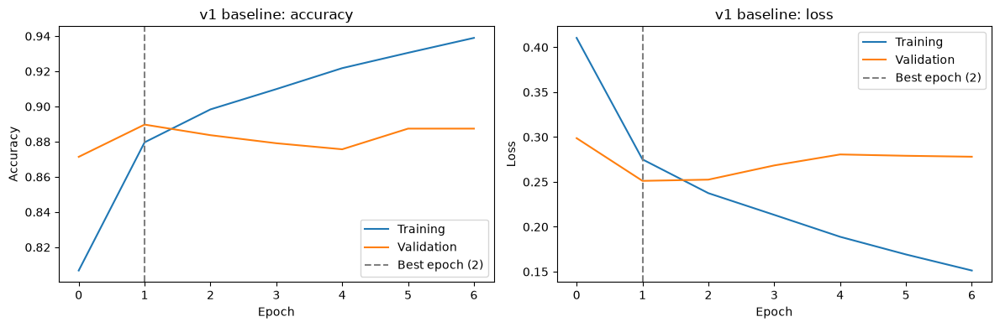

At the best epoch -> train accuracy 0.880 | val accuracy 0.890 | gap -0.010


In [22]:
# Plot the training vs validation curves (reusable for v2 and v3)
import matplotlib.pyplot as plt

def plot_curves(history, title):
    h = history.history if hasattr(history, "history") else history
    best = int(np.argmin(h["val_loss"]))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(["accuracy", "loss"]):
        ax[i].plot(h[m], label="Training")
        ax[i].plot(h["val_" + m], label="Validation")
        ax[i].axvline(best, color="grey", linestyle="--", label=f"Best epoch ({best + 1})")
        ax[i].set_xlabel("Epoch"); ax[i].set_ylabel(m.capitalize()); ax[i].legend()
        ax[i].set_title(f"{title}: {m}")
    plt.tight_layout(); plt.show()
    print(f"At the best epoch -> train accuracy {h['accuracy'][best]:.3f} | val accuracy {h['val_accuracy'][best]:.3f} "
          f"| gap {h['accuracy'][best] - h['val_accuracy'][best]:.3f}")

plot_curves(history_v1, "v1 baseline")

What this shows:

The curves split apart after epoch 2. The training loss keeps falling while the validation loss
turns upward, the classic pattern of overfitting. By epoch 7 the gap is 5.2 percentage points (93.9% vs 88.7%). At the best epoch, validation accuracy is slightly above training accuracy (gap −0.010). This is normal: the training score is averaged over the whole epoch while the weights are still improving, but the validation score is measured at the end of the epoch. 

Conclusion: v1 stops learning useful features after only 2 epochs, so it needs regularisation (methods that make memorising harder).

##### 3.2 Evaluating v1 on the Validation Set
Accuracy alone can hide problems, so several measures are used. "Positive" means female (1):
- Accuracy: share of all photos classified correctly.
- Precision: of the photos the model called female, the share that really are female.
- Recall: of the photos that really are female, the share the model found.
- F1-score: balances precision and recall in one number.
- ROC-AUC: how well the model ranks female above male photos across all thresholds (0.5 = guessing, 1 = perfect).
- Confusion matrix: a 2 × 2 table of correct and wrong predictions for each gender.

The EDA showed that gender is strongly linked to age group and ethnicity (1.5), so accuracy is also checked
for each group. This shows whether the model works equally well for everyone. The test set is still not used.

--- v1 (validation) ---
accuracy: 0.890  precision: 0.863  recall: 0.914  f1: 0.888  roc_auc: 0.962


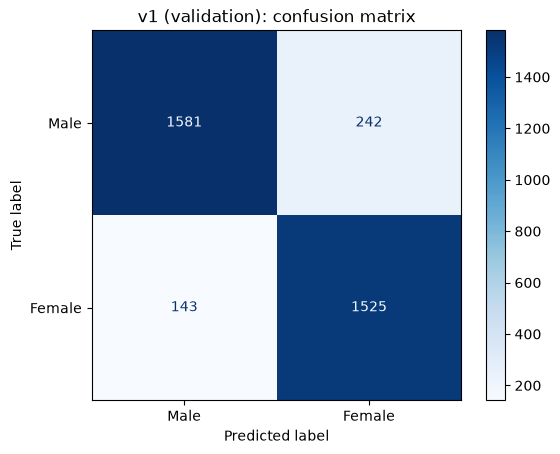


Accuracy by gender (overall 0.890):
        photos  accuracy
gender                  
Female    1668     0.914
Male      1823     0.867

Accuracy by age_group (overall 0.890):
                        photos  accuracy
age_group                               
1. Baby (0-2)              245     0.624
2. Child (3-12)            283     0.686
3. Teen (13-19)            170     0.871
4. Young adult (20-39)    1745     0.944
5. Adult (40-59)           658     0.956
6. Senior (60+)            390     0.859

Accuracy by ethnicity (overall 0.890):
           photos  accuracy
ethnicity                  
Asian         508     0.841
Black         666     0.911
Indian        582     0.909
Others        244     0.898
White        1491     0.888


In [ ]:
# One function to evaluate any model the same way (reused for v2, v3 and the final test)  #Helped by Claude, 2026
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

ETH_NAMES = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Others"}
results = {}        # stores the scores of every model version, for comparison later

def evaluate(model, X, y, meta_df, name, show=True):
    prob = model.predict(X, batch_size=256, verbose=0).ravel()     # probability of "female" for each photo
    pred = (prob >= 0.5).astype(int)                               # 0.5 or more -> predict female
    scores = {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred),
              "recall": recall_score(y, pred), "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob)}
    results[name] = scores

    # Accuracy for each group, to check fairness
    d = meta_df[["age_group", "ethnicity", "gender"]].copy()
    d["ethnicity"] = d["ethnicity"].map(ETH_NAMES)
    d["gender"] = d["gender"].map({0: "Male", 1: "Female"})
    d["correct"] = (pred == y)
    groups = {col: d.groupby(col)["correct"].agg(photos="count", accuracy="mean").round(3)
              for col in ["gender", "age_group", "ethnicity"]}

    if show:
        print(f"--- {name} ---")
        print("  ".join(f"{k}: {v:.3f}" for k, v in scores.items()))
        ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["Male", "Female"]).plot(cmap="Blues")
        plt.title(f"{name}: confusion matrix"); plt.show()
        for col, tbl in groups.items():
            print(f"\nAccuracy by {col} (overall {scores['accuracy']:.3f}):")
            print(tbl.to_string())
    return prob, pred, groups

prob_v1, pred_v1, groups_v1 = evaluate(model_v1, X_val, y_val, val_meta, "v1 (validation)")

What this shows:
- Overall: 89.0% accuracy, F1 0.888 and ROC-AUC 0.962, a strong start for a small model trained in under 2 minutes.
- Bias towards "female": recall (0.914) is higher than precision (0.863). The model labelled 1,767 photos female, but only 1,668 are. It wrongly called 242 men women, but only 143 women men, so men are classified less accurately (86.7% vs 91.4%).
- Age is the biggest weakness: accuracy is 94 - 96% for adults aged 20 - 59 but only 62.4% for babies and 68.6% for children, as the EDA predicted (1.12). Seniors (85.9%) are also below average.
- Ethnicity: accuracy ranges from 84.1% (Asian) to 91.1% (Black). This needs checking before drawing conclusions, because the age mix differs between groups (see 3.3).

Note: the validation set was used to choose when to stop training, so these scores may be slightly optimistic. The locked test set will give the final, unbiased score.

##### 3.3 Critical Check: Is the Model Learning Anything About Babies, and Is the Ethnicity Gap Really About Age?
Two questions:
1. Is the model better than guessing for each age group? If 62% of babies are boys, a "model" that always answers "male" already scores 62%. The real skill is the gain over that guess.
2. Is the lower accuracy for Asian faces caused by ethnicity, or by age?** If one group contains more babies and children, it will score lower even if the model treats all ethnicities the same. This is a confounding variable: a hidden factor (age) linked to both the group and the result.

In [24]:
# Compare the model with simply guessing the most common gender in each age group
d = val_meta.copy()
d["correct"] = (pred_v1 == y_val)
d["ethnicity"] = d["ethnicity"].map(ETH_NAMES)
d["under_13"] = d["age"] <= 12

age = d.groupby("age_group").agg(photos=("correct", "size"),
                                 female_share=("gender", "mean"),
                                 model_accuracy=("correct", "mean"))
age["always_guess_majority"] = np.maximum(age["female_share"], 1 - age["female_share"])   # accuracy of the "lazy" guess
age["gain_over_guess"] = age["model_accuracy"] - age["always_guess_majority"]
print("Model vs guessing, by age group:")
print(age.round(3).to_string())

# Accuracy by ethnicity for everyone, and again for ages 13+ only (removes the effect of babies and children)
eth = d.groupby("ethnicity").agg(photos=("correct", "size"),
                                 share_under_13=("under_13", "mean"),
                                 accuracy_all=("correct", "mean"))
eth["accuracy_13_plus"] = d[~d["under_13"]].groupby("ethnicity")["correct"].mean()
print("\nAccuracy by ethnicity, with and without children:")
print(eth.round(3).sort_values("share_under_13", ascending=False).to_string())

Model vs guessing, by age group:
                        photos  female_share  model_accuracy  always_guess_majority  gain_over_guess
age_group                                                                                           
1. Baby (0-2)              245         0.384           0.624                  0.616            0.008
2. Child (3-12)            283         0.601           0.686                  0.601            0.085
3. Teen (13-19)            170         0.524           0.871                  0.524            0.347
4. Young adult (20-39)    1745         0.528           0.944                  0.528            0.416
5. Adult (40-59)           658         0.340           0.956                  0.660            0.296
6. Senior (60+)            390         0.436           0.859                  0.564            0.295

Accuracy by ethnicity, with and without children:
           photos  share_under_13  accuracy_all  accuracy_13_plus
ethnicity                                 

What this shows:
- Babies: v1 scores 62.4%, but always guessing "male" would score 61.6%. The gain is only 0.8 points, so v1 has learned almost nothing about babies' gender. For children the gain is 8.5 points, and for teens to seniors it is 30–42 points. The model's skill comes almost entirely from faces aged 13 and over.
- Ethnicity: with children removed, Asian accuracy rises from 84.1% to 91.8%, and the gap to the best group shrinks from 7.0 to 4.2 points. Asian photos contain the most children (28.3%), so most of the "ethnicity gap" was really an age effect. Age is a confounding variable. Among ages 13+, Asian (91.8%), Black (92.2%) and White (92.5%) faces score similarly, while Indian (96.0%) and Others (95.8%) score highest. A smaller gap remains and is tracked in v2 and v3.

Conclusion: reporting accuracy by ethnicity alone would have wrongly blamed ethnicity. Results are checked for confounding before conclusions are drawn.

#### STEP 4: Model v2, Fixing the Weaknesses of v1
Each change in v2 targets a specific problem found in v1:

| Weakness in v1 | Change in v2 | How it helps |
|---|---|---|
| Overfits after 2 epochs | Data augmentation: random flips, small rotations, zoom, shifts, brightness and contrast changes | Every epoch the model sees slightly different versions of each photo, so it cannot memorise them [Shorten & Khoshgoftaar, 2019] |
| Lighting varies and differs between groups (EDA 1.9) | Random brightness and contrast in the augmentation | Teaches the model that lighting is not a gender cue |
| 92% of weights in one dense layer | Global average pooling replaces Flatten | Averages each pattern map into one number: 8,192 inputs become 256, so far fewer weights can memorise [Lin et al., 2014] |
| Memorisation in the dense layer | Dropout (50%) | Randomly switches off half the neurons during training, so the model cannot rely on any single one [Srivastava et al., 2014] |
| Deeper model is harder to train | Batch normalisation after each convolution | Keeps the values flowing between layers on a steady scale, so training is faster and more stable [Ioffe & Szegedy, 2015] |
| Only 3 convolution blocks | 4th block (256 filters) | More capacity to learn fine face features, now that overfitting is controlled |
| Learning stalls early | Reduce learning rate on plateau (halve it after 3 epochs with no improvement); up to 60 epochs, early-stopping patience 8 | Smaller steps let the model fine-tune once progress slows |

Augmentation happens inside the model and only during training. Validation and test photos are never altered.

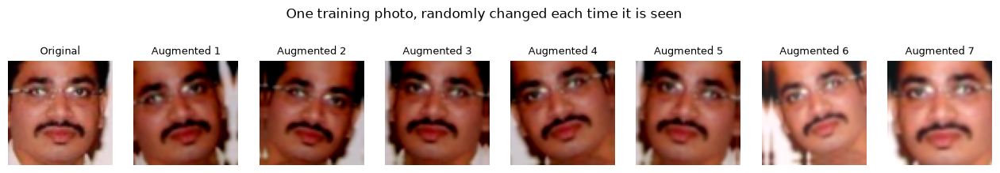

In [25]:
# Define the random changes, then show what they do to one training photo
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),          # mirror left-right (a face is still the same gender when mirrored)
    layers.RandomRotation(0.05),              # tilt up to ±18 degrees
    layers.RandomZoom(0.10),                  # zoom in or out up to 10%
    layers.RandomTranslation(0.05, 0.05),     # shift up/down/left/right up to 5%
    layers.RandomBrightness(0.15),            # lighter or darker (up to 15%)
    layers.RandomContrast(0.15),              # more or less contrast (up to 15%)
], name="augmentation")
# No vertical flip: upside-down faces never appear in real photos, so they would only confuse the model

i = 10
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(X_train[i]); axes[0].set_title("Original", fontsize=9); axes[0].axis("off")
for k in range(1, 8):
    aug = augment(X_train[i:i + 1], training=True)[0].numpy()     # training=True switches the random changes on
    axes[k].imshow(np.clip(aug, 0, 255).astype("uint8")); axes[k].set_title(f"Augmented {k}", fontsize=9); axes[k].axis("off")
plt.suptitle("One training photo, randomly changed each time it is seen", y=1.05)
plt.show()

What this shows:

Each time the photo is used in training it is randomly mirrored, tilted, zoomed, shifted, and made
lighter or darker. The man is still clearly recognisable: his glasses, moustache and face shape are unchanged, so the label stays correct. This is the rule for safe augmentation. Over 40 epochs the model sees the same 16,292 faces in thousands of different versions, so memorising one exact photo no longer helps.

In [ ]:
# Build v2: augmentation + 4 convolution blocks with batch normalisation + global average pooling + dropout. # Helped by Claude, 2026
keras.utils.set_random_seed(42)

def conv_block(filters):
    """Convolution -> batch normalisation -> ReLU -> max pooling."""
    return [layers.Conv2D(filters, 3, padding="same", use_bias=False),   # no bias: batch norm adds its own shift
            layers.BatchNormalization(),                                 # keeps values on a steady scale
            layers.Activation("relu"),
            layers.MaxPooling2D()]

def build_v2():
    model = keras.Sequential(
        [keras.Input(shape=(64, 64, 3)),
         augment,                                    # random changes (training only)
         layers.Rescaling(1.0 / 255)]
        + conv_block(32)                             # 64 -> 32
        + conv_block(64)                             # 32 -> 16
        + conv_block(128)                            # 16 -> 8
        + conv_block(256)                            # 8  -> 4
        + [layers.GlobalAveragePooling2D(),          # 4 x 4 x 256 -> 256 numbers (one average per pattern)
           layers.Dense(128, activation="relu"),
           layers.Dropout(0.5),                      # switch off 50% of neurons at random during training
           layers.Dense(1, activation="sigmoid")],
        name="v2_regularised_cnn")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

model_v2 = build_v2()
model_v2.summary()

Model: "v2_regularised_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 422,881 (1.61 MB)

 Trainable params: 421,921 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

What this shows:

v2 has 422,881 weights, 63% fewer than v1, even though it has an extra convolution block. The saving comes from global average pooling: the dense layer now receives 256 numbers instead of 8,192, so it has
32,896 weights instead of 1,048,704. The 960 non-trainable values are batch normalisation's running averages (a mean and a variance for each of the 480 filters). They are updated automatically rather than learned. Most of v2's weights are now in the convolution layers, which detect face features, not in the layer that memorised the training photos in v1.

In [ ]:
# Train v2 with early stopping and a learning rate that halves when progress stalls. # Helped by Claude, 2026
timer_v2 = EpochTimer()
callbacks_v2 = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    timer_v2,
]

t = time.time()
history_v2 = model_v2.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=60, batch_size=64, callbacks=callbacks_v2, verbose=2)
print(f"\nTotal training time: {(time.time() - t) / 60:.1f} minutes | "
      f"average {np.mean(timer_v2.times):.0f} s per epoch | epochs run: {len(timer_v2.times)}")
print("Best epoch (lowest validation loss):", int(np.argmin(history_v2.history["val_loss"])) + 1)

model_v2.save("model_v2.keras")
pd.DataFrame(history_v2.history).to_csv("history_v2.csv", index=False)

Epoch 1/60
255/255 - 37s - 145ms/step - accuracy: 0.6985 - auc: 0.7604 - loss: 0.5855 - val_accuracy: 0.4789 - val_auc: 0.8165 - val_loss: 0.9205 - learning_rate: 0.0010
Epoch 2/60
255/255 - 32s - 125ms/step - accuracy: 0.8001 - auc: 0.8775 - loss: 0.4398 - val_accuracy: 0.8293 - val_auc: 0.9262 - val_loss: 0.3766 - learning_rate: 0.0010
Epoch 3/60
255/255 - 32s - 126ms/step - accuracy: 0.8322 - auc: 0.9117 - loss: 0.3768 - val_accuracy: 0.8573 - val_auc: 0.9393 - val_loss: 0.3456 - learning_rate: 0.0010
Epoch 4/60
255/255 - 32s - 124ms/step - accuracy: 0.8386 - auc: 0.9210 - loss: 0.3576 - val_accuracy: 0.7445 - val_auc: 0.9337 - val_loss: 0.7172 - learning_rate: 0.0010
Epoch 5/60
255/255 - 32s - 126ms/step - accuracy: 0.8490 - auc: 0.9308 - loss: 0.3367 - val_accuracy: 0.8207 - val_auc: 0.9450 - val_loss: 0.4623 - learning_rate: 0.0010
Epoch 6/60
255/255 - 32s - 127ms/step - accuracy: 0.8585 - auc: 0.9384 - loss: 0.3181 - val_accuracy: 0.8625 - val_auc: 0.9480 - val_loss: 0.3033 - le

What this shows:

v2 trained for 43 epochs (24.0 minutes, 33 seconds per epoch), with the best validation loss at
epoch 35 (0.203). Each epoch is about twice as slow as v1 because of the augmentation and the extra block.
- Early epochs were unstable. Validation accuracy was only 47.9% after epoch 1 and dropped to 74.5% at epoch 4. At the start, batch normalisation's running averages have not settled and the learning rate is high, so the model's behaviour on new photos jumps around.
- Reducing the learning rate fixed this. It was halved several times (from 0.001 down to 0.0000156). Each smaller step let the model settle into better weights, and the validation scores became smooth.

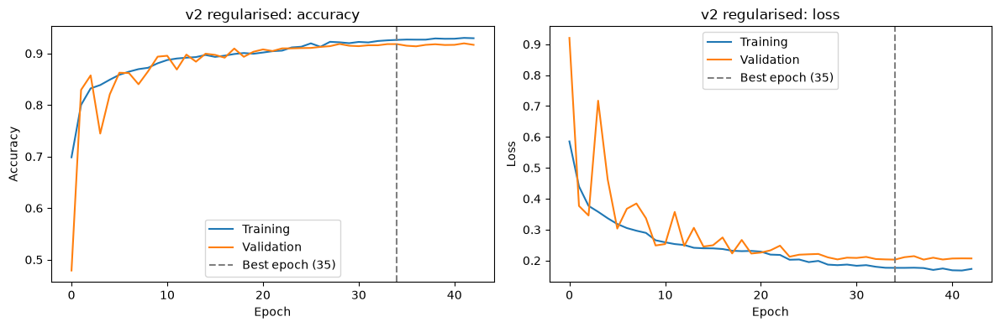

At the best epoch -> train accuracy 0.926 | val accuracy 0.918 | gap 0.008
--- v2 (validation) ---
accuracy: 0.918  precision: 0.913  recall: 0.916  f1: 0.914  roc_auc: 0.976


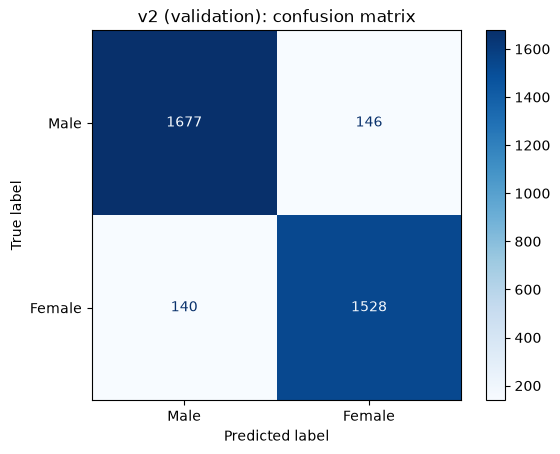


Accuracy by gender (overall 0.918):
        photos  accuracy
gender                  
Female    1668     0.916
Male      1823     0.920

Accuracy by age_group (overall 0.918):
                        photos  accuracy
age_group                               
1. Baby (0-2)              245     0.678
2. Child (3-12)            283     0.753
3. Teen (13-19)            170     0.900
4. Young adult (20-39)    1745     0.967
5. Adult (40-59)           658     0.959
6. Senior (60+)            390     0.910

Accuracy by ethnicity (overall 0.918):
           photos  accuracy
ethnicity                  
Asian         508     0.874
Black         666     0.932
Indian        582     0.923
Others        244     0.885
White        1491     0.930

Overall scores:
                 accuracy  precision  recall     f1  roc_auc
v1 (validation)     0.890      0.863   0.914  0.888    0.962
v2 (validation)     0.918      0.913   0.916  0.914    0.976

Accuracy by gender:
        photos     v1     v2  change
g

In [28]:
# Learning curves and validation results for v2
plot_curves(history_v2, "v2 regularised")
prob_v2, pred_v2, groups_v2 = evaluate(model_v2, X_val, y_val, val_meta, "v2 (validation)")

# Side-by-side comparison of v1 and v2
print("\nOverall scores:")
print(pd.DataFrame(results).T.round(3).to_string())
for col in ["gender", "age_group", "ethnicity"]:
    comp = pd.DataFrame({"photos": groups_v1[col]["photos"],
                         "v1": groups_v1[col]["accuracy"],
                         "v2": groups_v2[col]["accuracy"]})
    comp["change"] = comp["v2"] - comp["v1"]
    print(f"\nAccuracy by {col}:")
    print(comp.round(3).to_string())

What this shows:

| | v1 | v2 | Change |
|---|---|---|---|
| Accuracy | 0.890 | **0.918** | +2.8 points |
| Precision | 0.863 | **0.913** | +5.0 |
| Recall | 0.914 | **0.916** | +0.2 |
| F1 | 0.888 | **0.914** | +2.6 |
| ROC-AUC | 0.962 | **0.976** | +1.4 |
| Train–validation gap at the best epoch | 5.2 points (epoch 7) | **0.8 points** | Overfitting removed |
| Wrong predictions | 385 | **286** | 26% fewer errors |

- Overfitting is fixed: the training and validation curves now move together for the whole of training.
- The bias towards "female" is gone: v2 wrongly labels 146 men and 140 women (v1: 242 and 143). Male accuracy rose by 5.3 points to 92.0%, now level with female accuracy (91.6%). Precision and recall are now balanced.
- Every age group improved, and the weakest improved most: babies +5.4 (now 6.2 points better than guessing), children +6.7 and seniors +5.1. Babies (67.8%) and children (75.3%) are still far behind adults (96 - 97%). Augmentation cannot add information that is not in the photo.
- Ethnicity: four groups improved. "Others" fell by 1.3 points, but it has only 244 photos, so 1.3 points is about 3 photos. The normal random variation (standard error) for that group is about ±1.9 points, so this change is not meaningful.
- Cost: training took 24.0 minutes instead of 1.8, about 13 times longer, for 26% fewer errors.

Next: v2 now fits the training and validation data equally well, so the next limit is how much the model knows about faces. It has learned from only 16,292 photos. v3 uses transfer learning: it starts from a network that has already learned visual features from 1.2 million images.

#### STEP 5: Model v3, Transfer Learning with MobileNetV2

Transfer learning means reusing a model that was already trained on a large dataset for a new task, like a trained chef learning a new recipe instead of learning to cook from scratch. The early layers of any image model learn general features such as edges, textures and shapes, which are useful for almost any image task.

MobileNetV2 is a CNN trained on ImageNet (about 1.2 million photos of 1,000 kinds of object). It was designed to be small and fast enough for mobile phones, which makes it practical on a CPU.

Training happens in two stages:
1. Train the new head only: the pre-trained layers are frozen (their weights cannot change), and only a new final layer is trained to turn MobileNetV2's features into a gender prediction. This stops large early mistakes from damaging the pre-trained features.
2. Fine-tune: the top 30 layers of MobileNetV2 are unfrozen and trained with a very small learning rate (0.00001),so that they adjust gently to faces.

| Setting | Value | Reason |
|---|---|---|
| Input | 64 × 64, enlarged to 96 × 96 inside the model | 96 × 96 is the smallest size MobileNetV2 was trained at |
| Pixel scale | −1 to 1 | The scale MobileNetV2 was trained with |
| Augmentation | Same as v2 | Already shown to prevent overfitting |
| Head | Global average pooling -> dropout 30% -> sigmoid | Small, so it cannot memorise |
| Stage 1 | Adam 0.001, up to 15 epochs, early stopping patience 4 | Only the head learns |
| Stage 2 | Adam 0.00001, up to 20 epochs, early stopping patience 5, learning-rate reduction | Small steps protect the pre-trained features |

In [ ]:
# Build v3: a pre-trained MobileNetV2 "backbone" with a new gender "head". # Helped by Claude, 2026
keras.utils.set_random_seed(42)

# Download MobileNetV2 trained on ImageNet, without its original 1,000-object output layer
base = keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights="imagenet")
base.trainable = False                                   # Stage 1: freeze all pre-trained weights

inputs  = keras.Input(shape=(64, 64, 3))
x = augment(inputs)                                      # same random changes as v2 (training only)
x = layers.Resizing(96, 96)(x)                           # enlarge 64x64 -> 96x96, the size MobileNetV2 expects
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)          # pixels 0-255 -> -1 to 1, the scale MobileNetV2 was trained on
x = base(x, training=False)                              # keep MobileNetV2's batch normalisation in "use" mode
x = layers.GlobalAveragePooling2D()(x)                   # 3 x 3 x 1280 feature maps -> 1,280 numbers
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)       # probability of "female"
model_v3 = keras.Model(inputs, outputs, name="v3_mobilenetv2")

model_v3.summary()
print(f"Trainable weights in stage 1: {sum(np.prod(w.shape) for w in model_v3.trainable_weights):,}")

Model: "v3_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable weights in stage 1: 1,281


What this shows:

v3 has 2,259,265 weights, five times more than v2. Almost all of them are MobileNetV2's pre-trained weights, which are frozen in stage 1. Only 1,281 weights (0.06%) are trained in stage 1: one weight for
each of MobileNetV2's 1,280 features, plus one extra. The final feature map is only 3 × 3, because MobileNetV2 shrinks the image 32 times. This is a warning sign that 96 × 96 is very small for this network, which was designed for
224 × 224 images.

In [30]:
# Stage 1: only the new head learns; MobileNetV2 stays frozen
model_v3.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                 loss="binary_crossentropy",
                 metrics=["accuracy", keras.metrics.AUC(name="auc")])

timer_v3a = EpochTimer()
t = time.time()
history_v3a = model_v3.fit(X_train, y_train, validation_data=(X_val, y_val),
                           epochs=15, batch_size=64, verbose=2,
                           callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                                                    restore_best_weights=True), timer_v3a])
print(f"\nStage 1: {(time.time() - t) / 60:.1f} minutes | {np.mean(timer_v3a.times):.0f} s per epoch | "
      f"epochs: {len(timer_v3a.times)} | best val accuracy: {max(history_v3a.history['val_accuracy']):.3f}")
model_v3.save("model_v3_stage1.keras")

Epoch 1/15
255/255 - 36s - 143ms/step - accuracy: 0.6876 - auc: 0.7498 - loss: 0.6089 - val_accuracy: 0.7777 - val_auc: 0.8646 - val_loss: 0.4831
Epoch 2/15
255/255 - 29s - 113ms/step - accuracy: 0.7559 - auc: 0.8316 - loss: 0.5061 - val_accuracy: 0.7963 - val_auc: 0.8797 - val_loss: 0.4585
Epoch 3/15
255/255 - 29s - 114ms/step - accuracy: 0.7667 - auc: 0.8441 - loss: 0.4892 - val_accuracy: 0.8069 - val_auc: 0.8862 - val_loss: 0.4349
Epoch 4/15
255/255 - 29s - 113ms/step - accuracy: 0.7671 - auc: 0.8467 - loss: 0.4855 - val_accuracy: 0.8069 - val_auc: 0.8890 - val_loss: 0.4315
Epoch 5/15
255/255 - 32s - 126ms/step - accuracy: 0.7717 - auc: 0.8488 - loss: 0.4824 - val_accuracy: 0.8104 - val_auc: 0.8903 - val_loss: 0.4326
Epoch 6/15
255/255 - 32s - 127ms/step - accuracy: 0.7712 - auc: 0.8510 - loss: 0.4787 - val_accuracy: 0.8098 - val_auc: 0.8937 - val_loss: 0.4323
Epoch 7/15
255/255 - 30s - 117ms/step - accuracy: 0.7693 - auc: 0.8475 - loss: 0.4851 - val_accuracy: 0.8172 - val_auc: 0.89

What this shows:

With MobileNetV2 frozen, validation accuracy reached 81.8% and then flattened from about epoch 5, which is well below v1 (89.0%). Training took 7.7 minutes (31 s per epoch). Training accuracy (about 77.5%) is
below validation accuracy because dropout and augmentation are only active during training.

Meaning:MobileNetV2's features were learned on ImageNet's 1,000 object types, such as animals, vehicles and tools,none of which is a face. Features from the deepest layers of a pre-trained network are the most specific to its original task and transfer least well to a different one. A simple head on top of these features cannot separate male from female faces well.

In [31]:
# Stage 2: unfreeze the top 30 layers of MobileNetV2 and train them very gently
base.trainable = True
for layer in base.layers[:-30]:          # everything except the last 30 layers stays frozen
    layer.trainable = False
print(f"Trainable weights in stage 2: {sum(np.prod(w.shape) for w in model_v3.trainable_weights):,}")

# Recompile so the change takes effect; learning rate is 100x smaller than stage 1
model_v3.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                 loss="binary_crossentropy",
                 metrics=["accuracy", keras.metrics.AUC(name="auc")])

timer_v3b = EpochTimer()
t = time.time()
history_v3b = model_v3.fit(X_train, y_train, validation_data=(X_val, y_val),
                           epochs=20, batch_size=64, verbose=2,
                           callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
                                      keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                                                        min_lr=1e-6, verbose=1),
                                      timer_v3b])
print(f"\nStage 2: {(time.time() - t) / 60:.1f} minutes | {np.mean(timer_v3b.times):.0f} s per epoch | "
      f"epochs: {len(timer_v3b.times)}")
model_v3.save("model_v3.keras")

# Join the two stages into one history, for plotting
history_v3 = {k: history_v3a.history[k] + history_v3b.history[k]
              for k in ["accuracy", "val_accuracy", "loss", "val_loss"]}
pd.DataFrame(history_v3).to_csv("history_v3.csv", index=False)
print("Stage 2 starts at epoch", len(history_v3a.history["loss"]) + 1)

Trainable weights in stage 2: 1,527,681
Epoch 1/20
255/255 - 53s - 208ms/step - accuracy: 0.7026 - auc: 0.7771 - loss: 0.7449 - val_accuracy: 0.8195 - val_auc: 0.8977 - val_loss: 0.4065 - learning_rate: 1.0000e-05
Epoch 2/20
255/255 - 39s - 152ms/step - accuracy: 0.7541 - auc: 0.8330 - loss: 0.5927 - val_accuracy: 0.8276 - val_auc: 0.9030 - val_loss: 0.4009 - learning_rate: 1.0000e-05
Epoch 3/20
255/255 - 39s - 151ms/step - accuracy: 0.7718 - auc: 0.8532 - loss: 0.5412 - val_accuracy: 0.8298 - val_auc: 0.9090 - val_loss: 0.3963 - learning_rate: 1.0000e-05
Epoch 4/20
255/255 - 39s - 151ms/step - accuracy: 0.7832 - auc: 0.8668 - loss: 0.5065 - val_accuracy: 0.8333 - val_auc: 0.9143 - val_loss: 0.3901 - learning_rate: 1.0000e-05
Epoch 5/20
255/255 - 41s - 160ms/step - accuracy: 0.7925 - auc: 0.8784 - loss: 0.4793 - val_accuracy: 0.8396 - val_auc: 0.9202 - val_loss: 0.3810 - learning_rate: 1.0000e-05
Epoch 6/20
255/255 - 40s - 157ms/step - accuracy: 0.8045 - auc: 0.8879 - loss: 0.4565 - va

What this shows:

Unfreezing the top 30 layers (1,527,681 trainable weights) raised validation accuracy from 81.8%
to 86.5% over 20 epochs (13.3 minutes, 40 s per epoch). However, validation loss fell in almost every epoch (0.407 -> 0.327), and early stopping never triggered. Training stopped because it reached the 20-epoch limit, not because it had finished learning. Training and validation accuracy are almost equal (86.0% vs 86.5%), so there is no overfitting.

The model is underfitting: it has not yet learned enough. The learning rate of 0.00001 was chosen to protect the pre-trained weights, but it was too cautious, and reducing it further (to 0.0000025) slowed learning even more.

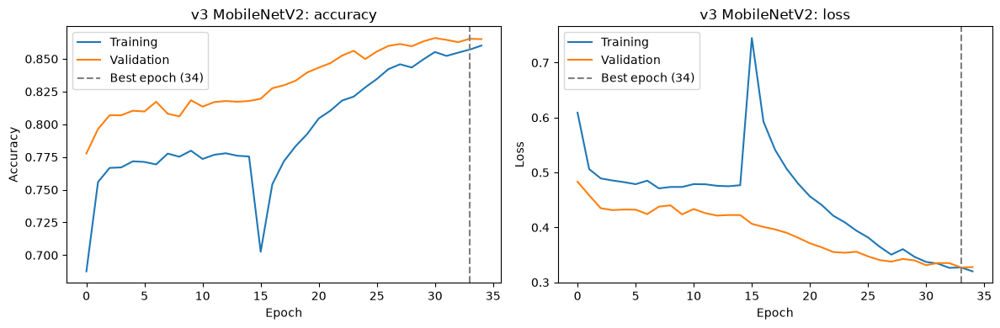

At the best epoch -> train accuracy 0.857 | val accuracy 0.865 | gap -0.008
--- v3 (validation) ---
accuracy: 0.865  precision: 0.887  recall: 0.823  f1: 0.854  roc_auc: 0.942


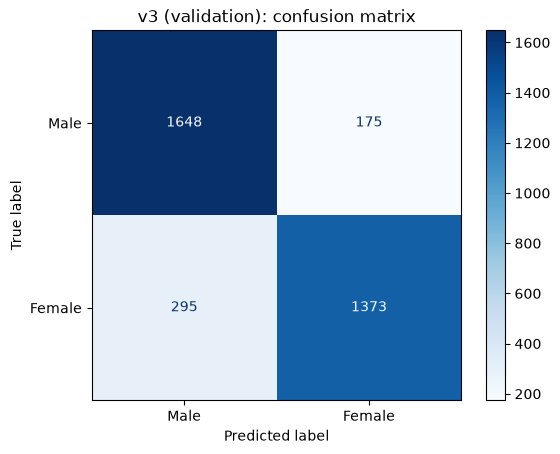


Accuracy by gender (overall 0.865):
        photos  accuracy
gender                  
Female    1668     0.823
Male      1823     0.904

Accuracy by age_group (overall 0.865):
                        photos  accuracy
age_group                               
1. Baby (0-2)              245     0.645
2. Child (3-12)            283     0.749
3. Teen (13-19)            170     0.865
4. Young adult (20-39)    1745     0.909
5. Adult (40-59)           658     0.895
6. Senior (60+)            390     0.841

Accuracy by ethnicity (overall 0.865):
           photos  accuracy
ethnicity                  
Asian         508     0.829
Black         666     0.860
Indian        582     0.892
Others        244     0.861
White        1491     0.871
                 accuracy  precision  recall     f1  roc_auc  weights  sec_per_epoch  total_minutes
v1 (validation)     0.890      0.863   0.914  0.888    0.962  1142081         15.354          1.791
v2 (validation)     0.918      0.913   0.916  0.914    0.97

In [32]:
# Learning curves and validation results for v3
plot_curves(history_v3, "v3 MobileNetV2")
prob_v3, pred_v3, groups_v3 = evaluate(model_v3, X_val, y_val, val_meta, "v3 (validation)")

# Compare all three versions: scores, size and training cost
comparison = pd.DataFrame(results).T
comparison["weights"]        = [model_v1.count_params(), model_v2.count_params(), model_v3.count_params()]
comparison["sec_per_epoch"]  = [np.mean(timer_v1.times), np.mean(timer_v2.times),
                                np.mean(timer_v3a.times + timer_v3b.times)]
comparison["total_minutes"]  = [sum(timer_v1.times) / 60, sum(timer_v2.times) / 60,
                                (sum(timer_v3a.times) + sum(timer_v3b.times)) / 60]
print(comparison.round(3).to_string())

for col in ["gender", "age_group", "ethnicity"]:
    comp = pd.DataFrame({"photos": groups_v1[col]["photos"], "v1": groups_v1[col]["accuracy"],
                         "v2": groups_v2[col]["accuracy"], "v3": groups_v3[col]["accuracy"]})
    print(f"\nAccuracy by {col}:")
    print(comp.round(3).to_string())

What this shows:
- v3 scored 86.5%, below v1 (89.0%) and v2 (91.8%), and its ROC-AUC was 0.942. A larger, pre-trained model is not automatically better.
- It now leans towards "male": recall is 0.823, so female faces are recognised correctly only 82.3% of the time, compared with 90.4% for male faces. This is the opposite of v1's bias.
- It dropped most on adults (young adults 90.9% vs 96.7% for v2). It held up better on children (74.9%, similar to v2) and babies (64.5%). With only 245 - 283 photos in these groups, those differences are within normal variation.
- Cost: 21.0 minutes of training, slightly less than v2 (24.0 minutes), for a clearly worse result.

Diagnosis - three reasons:
1. Domain gap: ImageNet contains objects, not faces, so the frozen features suit faces poorly (stage 1 stalled at 82%).
2. Low resolution: the 64 × 64 photos were enlarged to 96 × 96, which adds no new detail. MobileNetV2 is designed for 224 × 224 images, and here it saw blurry, enlarged ones.
3. Fine-tuning was too gentle: only 30 of 154 layers were unfrozen, at a very small learning rate, and the model was still improving when training stopped.

v3b fixes all three.

##### 5.1 Model v3b: Fixing v3

| Weakness in v3 | Change in v3b |
|---|---|
| Photos enlarged from 64 × 64 (no real detail added) | Load the real 96 × 96 photos from the original 200 × 200 images |
| Only the top 30 layers adapted to faces | Unfreeze all of MobileNetV2, so even its early layers can adapt to faces |
| Learning rate too small; still improving when stopped | Learning rate 0.0001 (10× higher), up to 15 epochs |
| A new head would start from random weights | Reuse the trained head from v3, so training starts from a sensible point |

Limitation: three things change at once, so any improvement cannot be credited to a single change. Testing each change separately would need about three more 30-minute runs on the CPU. I judged that too costly, because the goal is to see whether transfer learning can beat v2 at all.

In [33]:
# Load the same train/validation/test photos again, this time resized to 96 x 96 from the 200 x 200 originals
from PIL import Image

def load_images(paths, size):
    arr = np.zeros((len(paths), size, size, 3), dtype=np.uint8)
    for i, p in enumerate(paths):
        with Image.open(p) as img:
            arr[i] = np.asarray(img.convert("RGB").resize((size, size), Image.Resampling.BILINEAR))
    return arr

t = time.time()
X_train96 = load_images(train_meta["path"], 96)
X_val96   = load_images(val_meta["path"], 96)
X_test96  = load_images(test_meta["path"], 96)
print(f"Loaded in {time.time() - t:.0f} s | train {X_train96.shape} | val {X_val96.shape} | test {X_test96.shape}")
# The labels (y_train, y_val, y_test) are unchanged, because the photos are in exactly the same order

Loaded in 20 s | train (16292, 96, 96, 3) | val (3491, 96, 96, 3) | test (3492, 96, 96, 3)


In [34]:
# Build v3b: the same design as v3, but 96 x 96 input, all of MobileNetV2 trainable, and v3's trained head reused
keras.utils.set_random_seed(42)

# A fresh copy of the augmentation (the original is locked to 64 x 64 photos); the random changes are identical
augment96 = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.15),
], name="augmentation_96")

base_b = keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights="imagenet")
base_b.trainable = True                                   # every layer can now adapt to faces

inputs = keras.Input(shape=(96, 96, 3))
x = augment96(inputs)                                     # same random changes as v2 and v3
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)           # pixels 0-255 -> -1 to 1
x = base_b(x, training=False)                             # batch normalisation stays in "use" mode (safer when fine-tuning)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model_v3b = keras.Model(inputs, outputs, name="v3b_mobilenetv2_full")

# Copy the trained output layer from v3, so the head does not start from random weights
model_v3b.layers[-1].set_weights(model_v3.layers[-1].get_weights())

model_v3b.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
print(f"Trainable weights: {sum(np.prod(w.shape) for w in model_v3b.trainable_weights):,}")

Trainable weights: 2,225,153


What this shows:

v3b trains 2,225,153 weights, nearly all of MobileNetV2, compared with 1,281 in v3's stage 1 and
1,527,681 in its stage 2. Only MobileNetV2's batch-normalisation averages stay fixed. The 96 × 96 photos were loaded from the 200 × 200 originals in 20 seconds, so they contain real detail rather than enlarged pixels.

In [35]:
# Train v3b (expect roughly 1.5-2 minutes per epoch, so up to about 30 minutes)
timer_v3b2 = EpochTimer()
t = time.time()
history_v3b2 = model_v3b.fit(X_train96, y_train, validation_data=(X_val96, y_val),
                             epochs=15, batch_size=64, verbose=2,
                             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                                                      restore_best_weights=True),
                                        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                                                          min_lr=1e-6, verbose=1),
                                        timer_v3b2])
print(f"\nTotal: {(time.time() - t) / 60:.1f} minutes | {np.mean(timer_v3b2.times):.0f} s per epoch | "
      f"epochs: {len(timer_v3b2.times)} | best epoch: {int(np.argmin(history_v3b2.history['val_loss'])) + 1}")
model_v3b.save("model_v3b.keras")
pd.DataFrame(history_v3b2.history).to_csv("history_v3b.csv", index=False)

Epoch 1/15
255/255 - 156s - 614ms/step - accuracy: 0.7814 - auc: 0.8681 - loss: 0.5337 - val_accuracy: 0.7978 - val_auc: 0.8862 - val_loss: 0.4686 - learning_rate: 1.0000e-04
Epoch 2/15
255/255 - 120s - 472ms/step - accuracy: 0.8484 - auc: 0.9294 - loss: 0.3650 - val_accuracy: 0.6860 - val_auc: 0.8797 - val_loss: 0.7349 - learning_rate: 1.0000e-04
Epoch 3/15
255/255 - 119s - 466ms/step - accuracy: 0.8759 - auc: 0.9521 - loss: 0.2902 - val_accuracy: 0.8344 - val_auc: 0.9340 - val_loss: 0.3919 - learning_rate: 1.0000e-04
Epoch 4/15
255/255 - 118s - 463ms/step - accuracy: 0.8941 - auc: 0.9645 - loss: 0.2466 - val_accuracy: 0.8725 - val_auc: 0.9478 - val_loss: 0.3221 - learning_rate: 1.0000e-04
Epoch 5/15
255/255 - 117s - 460ms/step - accuracy: 0.9049 - auc: 0.9699 - loss: 0.2234 - val_accuracy: 0.8694 - val_auc: 0.9496 - val_loss: 0.4008 - learning_rate: 1.0000e-04
Epoch 6/15

Epoch 6: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
255/255 - 117s - 458ms/step - accurac

What this shows:

v3b trained for all 15 epochs in 30.1 minutes (120 s per epoch; the first epoch took 156 s while
TensorFlow set up). It is the slowest model by far, because it updates 2.2 million weights on photos with 2.25 times more pixels, on a CPU without a GPU.
- Learning was much faster than v3: validation accuracy reached 87.3% by epoch 4, already above v3's final 86.5% after 35 epochs.
- Epoch 2 dipped to 68.6%: the first large updates to every layer briefly disrupted the pre-trained features before the model recovered. v2 behaved similarly in its early epochs.
- The learning rate was halved at epochs 6 and 9, and the best validation loss came in the last epoch (15). The model might have improved slightly more with more epochs, but each extra epoch costs almost 2 minutes.
- Overfitting returned: training accuracy reached 95.8% while validation stayed at about 90%, a gap of 5.0 points (v2: 0.8). With all 2.2 million weights free to change, the model began memorising the training photos.

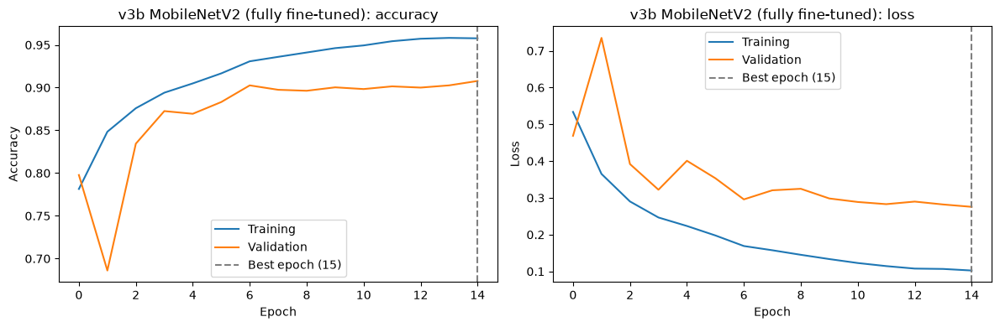

At the best epoch -> train accuracy 0.958 | val accuracy 0.908 | gap 0.050
--- v3b (validation) ---
accuracy: 0.908  precision: 0.908  recall: 0.897  f1: 0.903  roc_auc: 0.970


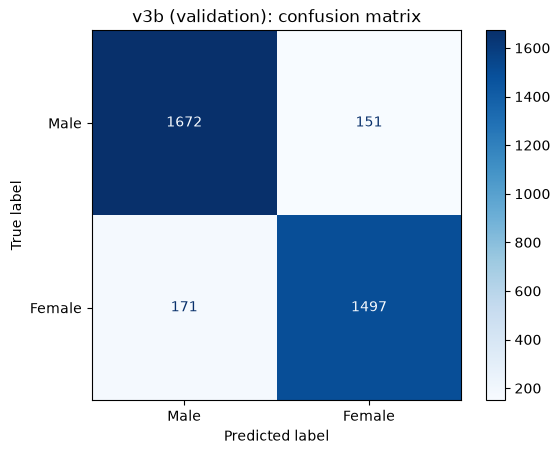


Accuracy by gender (overall 0.908):
        photos  accuracy
gender                  
Female    1668     0.897
Male      1823     0.917

Accuracy by age_group (overall 0.908):
                        photos  accuracy
age_group                               
1. Baby (0-2)              245     0.673
2. Child (3-12)            283     0.767
3. Teen (13-19)            170     0.888
4. Young adult (20-39)    1745     0.948
5. Adult (40-59)           658     0.950
6. Senior (60+)            390     0.915

Accuracy by ethnicity (overall 0.908):
           photos  accuracy
ethnicity                  
Asian         508     0.884
Black         666     0.931
Indian        582     0.893
Others        244     0.902
White        1491     0.912
                  accuracy  precision  recall     f1  roc_auc  weights  total_minutes
v1 (validation)      0.890      0.863   0.914  0.888    0.962  1142081          1.791
v2 (validation)      0.918      0.913   0.916  0.914    0.976   422881         23.969
v

In [36]:
# Learning curves, validation results, and the full comparison
plot_curves(history_v3b2, "v3b MobileNetV2 (fully fine-tuned)")
prob_v3b, pred_v3b, groups_v3b = evaluate(model_v3b, X_val96, y_val, val_meta, "v3b (validation)")

comparison = pd.DataFrame(results).T
comparison["weights"]       = [model_v1.count_params(), model_v2.count_params(),
                               model_v3.count_params(), model_v3b.count_params()]
comparison["total_minutes"] = [sum(timer_v1.times) / 60, sum(timer_v2.times) / 60,
                               (sum(timer_v3a.times) + sum(timer_v3b.times)) / 60, sum(timer_v3b2.times) / 60]
print(comparison.round(3).to_string())

for col in ["gender", "age_group", "ethnicity"]:
    comp = pd.DataFrame({"photos": groups_v1[col]["photos"], "v1": groups_v1[col]["accuracy"],
                         "v2": groups_v2[col]["accuracy"], "v3": groups_v3[col]["accuracy"],
                         "v3b": groups_v3b[col]["accuracy"]})
    print(f"\nAccuracy by {col}:")
    print(comp.round(3).to_string())

What this shows:
- The fixes worked: v3b scored 90.8% (v3: 86.5%), ROC-AUC 0.970 (v3: 0.942), and the bias towards "male" almost disappeared (female 89.7% vs male 91.7%, compared with v3's 82.3% vs 90.4%).
- It is still 1.0 point behind v2 (91.8%), with a lower ROC-AUC (0.970 vs 0.976). It also has 5 times more weights and takes about 25% longer to train (30.1 vs 24.0 minutes).
- v3b is slightly ahead of v2 for some harder groups: children (76.7% vs 75.3%), seniors (91.5% vs 91.0%), Asian (88.4% vs 87.4%) and Others (90.2% vs 88.5%). With 244 - 390 photos per group, these differences are within normal random variation (about +/-2 - 3 points).
- Why transfer learning did not win: UTKFace faces are already cropped and aligned, so a small CNN trained from scratch on 16,292 of them can learn what it needs. MobileNetV2's ImageNet features had to be largely re-learned for faces, and it is designed for 224 × 224 images, not 96 × 96.

Note: cells 5.2–5.4 were added and run after Step 6. They use only the training and validation sets, so the test set was still used only once for model decisions.

##### 5.2 Independent Label Audit

The labels were made by an algorithm and checked by one person, so they may contain mistakes. To test them
independently, 100 random training photos are shown with their gender labels, and each one is checked by eye.Test photos are not used, so the final exam stays unseen.

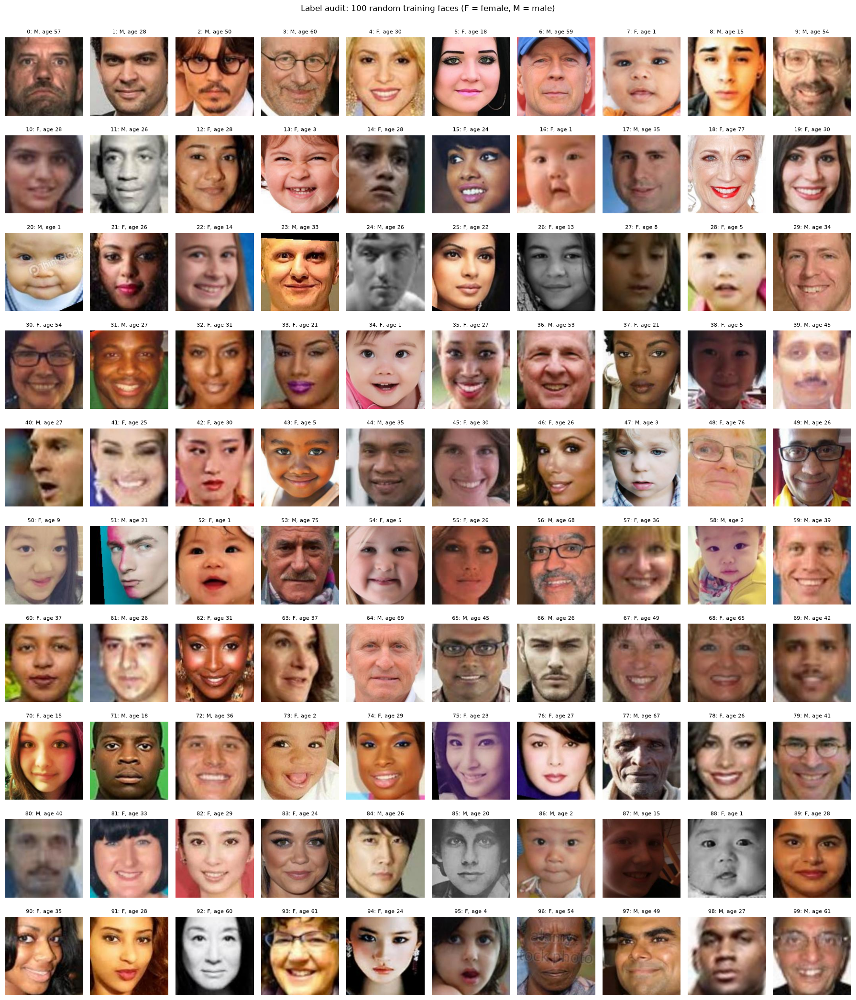

In [37]:
# Show 100 random training faces with their labels, to check by eye how many labels look wrong
from PIL import Image
audit = train_meta.sample(100, random_state=7).reset_index(drop=True)

fig, axes = plt.subplots(10, 10, figsize=(18, 21))
for i, (ax, (_, r)) in enumerate(zip(axes.ravel(), audit.iterrows())):
    ax.imshow(Image.open(r["path"]))
    ax.set_title(f"{i}: {'F' if r['gender'] == 1 else 'M'}, age {r['age']}", fontsize=8)
    ax.axis("off")
plt.suptitle("Label audit: 100 random training faces (F = female, M = male)", y=1.0)
plt.tight_layout(); plt.show()

What this shows:

9 of the 100 photos are babies (aged 0 - 2), whose gender cannot be judged from the face, so they were skipped. Of the other 91, none is clearly mislabelled, and 2 are doubtful: photo 14 (labelled female, age 28) and photo 96 (labelled female, age 54) could be male. This suggests that about 0 - 2% of labels are wrong across the dataset. With only 91 photos checked, the true rate could be up to about 3 - 8%, so this is a rough estimate.

Meaning: label errors are rare overall, but concentrated in the model's confident mistakes (6.4), where about 17 of the top 24 appear mislabelled. The model's most confident errors are therefore an efficient way to find bad labels: checking 24 photos found far more errors than checking 100 random ones.

##### 5.3 Is the Improvement Real? Repeating v1 with Different Random Seeds

Training starts from random weights, so the same model trained twice can score slightly differently. v1 is retrained three more times with different seeds. If the scores vary by much less than the 2.8-point gain from v1 to v2, the gain is real and not luck.

In [ ]:
# Retrain v1 with 3 new random seeds (about 2 minutes each) and measure how much the score varies. # Helped by Claude, 2026
seed_scores = [{"seed": 42, "accuracy": results["v1 (validation)"]["accuracy"],
                "roc_auc": results["v1 (validation)"]["roc_auc"]}]
for seed in [1, 2, 3]:
    keras.utils.set_random_seed(seed)
    m = build_v1()
    m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
    p = m.predict(X_val, batch_size=256, verbose=0).ravel()
    seed_scores.append({"seed": seed, "accuracy": accuracy_score(y_val, p >= 0.5), "roc_auc": roc_auc_score(y_val, p)})
    print(f"Seed {seed}: accuracy {seed_scores[-1]['accuracy']:.3f}")

seeds = pd.DataFrame(seed_scores)
print(seeds.round(3).to_string(index=False))
print(f"\nv1 accuracy across 4 seeds: mean {seeds['accuracy'].mean():.3f}, "
      f"spread (std) {seeds['accuracy'].std():.3f}, range {seeds['accuracy'].min():.3f}-{seeds['accuracy'].max():.3f}")
print(f"v1 -> v2 gain: {results['v2 (validation)']['accuracy'] - seeds['accuracy'].mean():.3f}")

Seed 1: accuracy 0.898
Seed 2: accuracy 0.897
Seed 3: accuracy 0.893
 seed  accuracy  roc_auc
   42     0.890    0.962
    1     0.898    0.962
    2     0.897    0.964
    3     0.893    0.964

v1 accuracy across 4 seeds: mean 0.895, spread (std) 0.004, range 0.890-0.898
v1 -> v2 gain: 0.024


What this shows:

Across four random seeds, v1 scored between 89.0% and 89.8% (average 89.5%, spread +/-0.4 points), and its ROC-AUC stayed at 0.962 - 0.964. Seed 42, used for the main v1, was actually the lowest, so the v1 results reported earlier are slightly pessimistic.
v2 (91.8%) beats the v1 average by 2.4 points, about 6 times the seed spread, and it is still 2.0 points above v1's best seed. The v1 - v2 improvement is real, not luck.

##### 5.4 An Alternative, Non-Deep-Learning Model: HOG + Logistic Regression

Before CNNs, faces were usually analysed with HOG (Histogram of Oriented Gradients). HOG divides the image into small cells and records which directions the edges point in each cell. A simple model such as logistic regression (used in Part 2) then classifies these numbers. This tests whether a CNN is really needed, or whether a classic method does almost as well.

In [ ]:
%pip install scikit-image # install the HOG library

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
    --------------------------------------- 0.3/11.9 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.9 MB 2.8 MB/s eta 0:00:04
   -------- ------------------------------- 2.6/11.9 MB 5.0 MB/s eta 0:00:02
   --------------------------- ------------ 8.1/11.9 MB 11.4 MB/s eta 0:00:01
   ---------------------------------------- 11.9/11.9 MB 13.5 MB/s  0:00:01
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 58.3 MB/s  0:00:00

   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   ---------------------------------------- 0/5 [tifffile]
   -------- ------------------------------- 1/5 [networkx]
   -------- -------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


HOG features per photo: 1764
Feature extraction + training: 0.5 minutes
--- HOG + LogReg (validation) ---
accuracy: 0.836  precision: 0.831  recall: 0.825  f1: 0.828  roc_auc: 0.916


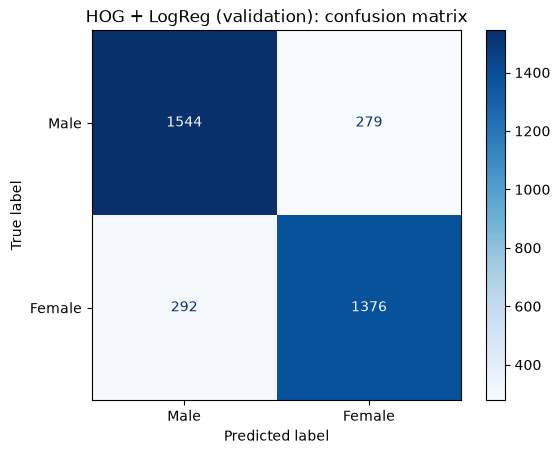


Accuracy by gender (overall 0.836):
        photos  accuracy
gender                  
Female    1668     0.825
Male      1823     0.847

Accuracy by age_group (overall 0.836):
                        photos  accuracy
age_group                               
1. Baby (0-2)              245     0.571
2. Child (3-12)            283     0.696
3. Teen (13-19)            170     0.847
4. Young adult (20-39)    1745     0.885
5. Adult (40-59)           658     0.906
6. Senior (60+)            390     0.764

Accuracy by ethnicity (overall 0.836):
           photos  accuracy
ethnicity                  
Asian         508     0.781
Black         666     0.857
Indian        582     0.852
Others        244     0.877
White        1491     0.833
                           accuracy  precision  recall     f1  roc_auc
v1 (validation)               0.890      0.863   0.914  0.888    0.962
v2 (validation)               0.918      0.913   0.916  0.914    0.976
v3 (validation)               0.865      0.887

In [ ]:
# Classic baseline: HOG edge-direction features + logistic regression
# (if scikit-image is missing, run:  pip install scikit-image  in the py311 environment). # Helped by Claude, 2026
from skimage.feature import hog
from skimage.color import rgb2gray
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def hog_features(X):
    """For each photo: convert to grey, split into 8x8-pixel cells, record 9 edge directions per cell."""
    return np.array([hog(rgb2gray(img), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
                     for img in X])

t = time.time()
H_train = hog_features(X_train)
print("HOG features per photo:", H_train.shape[1])

hog_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1))
hog_lr.fit(H_train, y_train)
print(f"Feature extraction + training: {(time.time() - t) / 60:.1f} minutes")

class SklearnModel:
    """Lets the scikit-learn model be scored by the same evaluate() function as the CNNs."""
    def __init__(self, pipe): self.pipe = pipe
    def predict(self, X, batch_size=None, verbose=0):
        return self.pipe.predict_proba(hog_features(X))[:, 1]

hog_model = SklearnModel(hog_lr)
prob_hog, pred_hog, groups_hog = evaluate(hog_model, X_val, y_val, val_meta, "HOG + LogReg (validation)")
print(pd.DataFrame(results).T.round(3).to_string())

What this shows:

HOG with logistic regression scored 83.6% (ROC-AUC 0.916) after only 0.5 minutes of training, using 1,764 edge-direction numbers per photo. This is far better than guessing, so simple edge shapes do carry
gender information. However, it is 5.4 points below v1 and 8.2 points below v2. It struggles most where the CNNs also struggle, but more badly: babies 57.1%, Asian faces 78.1% and seniors 76.4%.

Meaning: the CNN's ability to learn its own features(eyes, brows, jawline) is worth its extra cost. Hand-made edge features alone cannot match it.

##### 5.5 Choosing the Final Model

v2 and v3b are 1.0 point apart on the validation set. To check whether this gap is real or chance, McNemar's test is used. It looks only at the photos where the two models disagree: one is right and the other wrong. If the models were equally good, these disagreements would split roughly 50/50. A p-value below 0.05 means the split is too uneven to be chance. The final model is chosen here, before the test set is opened, so the test score cannot influence the choice.

In [42]:
# McNemar's test: are v2 and v3b really different on the validation set?
from scipy.stats import binomtest

def mcnemar_test(y, pred_a, pred_b, name_a, name_b):
    a_right, b_right = (pred_a == y), (pred_b == y)
    only_a = int(np.sum(a_right & ~b_right))     # photos only model A got right
    only_b = int(np.sum(~a_right & b_right))     # photos only model B got right
    p = binomtest(only_a, only_a + only_b, 0.5).pvalue
    print(f"{name_a} right & {name_b} wrong: {only_a} | {name_b} right & {name_a} wrong: {only_b} | p-value: {p:.4f}")
    return p

mcnemar_test(y_val, pred_v2, pred_v3b, "v2", "v3b")
mcnemar_test(y_val, pred_v2, pred_v1,  "v2", "v1")

v2 right & v3b wrong: 163 | v3b right & v2 wrong: 127 | p-value: 0.0397
v2 right & v1 wrong: 206 | v1 right & v2 wrong: 107 | p-value: 0.0000


2.3410854287956755e-08

What this shows:
- v2 vs v3b: of the 290 validation photos where they disagree, v2 is right on 163 and v3b on 127 (p = 0.040, just below 0.05), so on the validation set v2 is very likely genuinely better, not just luckier.
- v2 vs v1: v2 is right on 206 disagreements against v1's 107 (p < 0.0001), so retraining clearly worked.

Decision: v2 is the final model. It has the highest validation accuracy and ROC-AUC, it is significantly better than v3b, it has 5 times fewer weights (0.42 M vs 2.26 M) and it trains faster (24.0 vs 30.1 minutes). When two models are close, the smaller and cheaper one is the better choice.

#### STEP 6: Final Evaluation on the Test Set

The test set (3,492 photos) has not been used for any decision so far. v2 is the final model, chosen in 5.5. v1 and v3b are also scored on the test set for reference only; the choice is already fixed.

A single test score is still an estimate. A different set of 3,492 photos would give a slightly different score. To show how precise each score is, bootstrap 95% confidence intervals are calculated. The test set is resampled 1,000 times with replacement (some photos are picked twice, some not at all), the score is recalculated each time, and the middle 95% of those 1,000 scores is the interval.

--- v2 (TEST) ---
accuracy: 0.921  precision: 0.912  recall: 0.923  f1: 0.917  roc_auc: 0.978


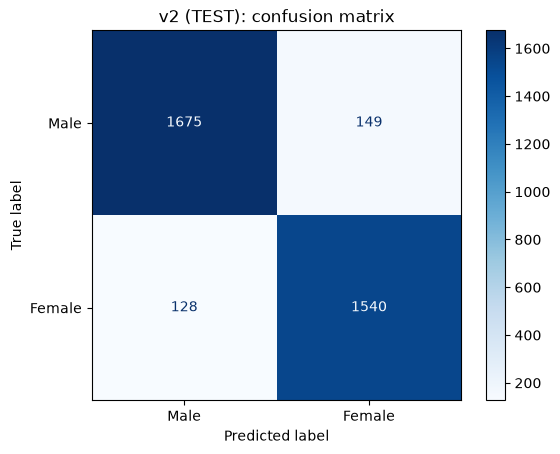


Accuracy by gender (overall 0.921):
        photos  accuracy
gender                  
Female    1668     0.923
Male      1824     0.918

Accuracy by age_group (overall 0.921):
                        photos  accuracy
age_group                               
1. Baby (0-2)              263     0.620
2. Child (3-12)            247     0.798
3. Teen (13-19)            169     0.923
4. Young adult (20-39)    1760     0.964
5. Adult (40-59)           709     0.970
6. Senior (60+)            344     0.916

Accuracy by ethnicity (overall 0.921):
           photos  accuracy
ethnicity                  
Asian         508     0.862
Black         667     0.936
Indian        582     0.930
Others        243     0.918
White        1492     0.931
Test scores with 95% bootstrap confidence intervals:
                       accuracy            precision               recall                   f1              roc_auc
model                                                                                     

2.3628842028853233e-05

In [ ]:
# Score the final model (and the two reference models) on the locked test set #Helped by Claude, 2026
prob_t2,  pred_t2,  groups_t2  = evaluate(model_v2,  X_test,   y_test, test_meta, "v2 (TEST)")
prob_t1,  pred_t1,  groups_t1  = evaluate(model_v1,  X_test,   y_test, test_meta, "v1 (TEST)",  show=False)
prob_t3b, pred_t3b, groups_t3b = evaluate(model_v3b, X_test96, y_test, test_meta, "v3b (TEST)", show=False)

# Bootstrap: resample the test set 1,000 times and recalculate the scores
rng = np.random.default_rng(42)
def bootstrap_ci(y, prob, n_boot=1000):
    pred = (prob >= 0.5).astype(int)
    scores = {"accuracy": [], "precision": [], "recall": [], "f1": [], "roc_auc": []}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))              # pick len(y) photos at random, with replacement
        scores["accuracy"].append(accuracy_score(y[idx], pred[idx]))
        scores["precision"].append(precision_score(y[idx], pred[idx]))
        scores["recall"].append(recall_score(y[idx], pred[idx]))
        scores["f1"].append(f1_score(y[idx], pred[idx]))
        scores["roc_auc"].append(roc_auc_score(y[idx], prob[idx]))
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in scores.items()}

rows = []
for name, prob in [("v1", prob_t1), ("v2 (final)", prob_t2), ("v3b", prob_t3b)]:
    ci = bootstrap_ci(y_test, prob)
    key = name.split(" ")[0] + " (TEST)"
    rows.append({"model": name, **{k: f"{results[key][k]:.3f} ({lo:.3f}-{hi:.3f})" for k, (lo, hi) in ci.items()}})
print("Test scores with 95% bootstrap confidence intervals:")
print(pd.DataFrame(rows).set_index("model").to_string())

print("\nValidation vs test accuracy (a big drop would mean the validation score was over-optimistic):")
for m in ["v1", "v2", "v3b"]:
    print(f"  {m}: validation {results[m + ' (validation)']['accuracy']:.3f} -> test {results[m + ' (TEST)']['accuracy']:.3f}")

print("\nMcNemar's test on the test set:")
mcnemar_test(y_test, pred_t2, pred_t3b, "v2", "v3b")
mcnemar_test(y_test, pred_t2, pred_t1,  "v2", "v1")

What this shows:

| Model | Accuracy (95% CI) | F1 (95% CI) | ROC-AUC (95% CI) |
|---|---|---|---|
| v1 | 0.900 (0.889–0.910) | 0.899 (0.887–0.909) | 0.965 (0.959–0.970) |
| **v2 (final)** | **0.921 (0.912–0.929)** | **0.917 (0.909–0.927)** | **0.978 (0.973–0.982)** |
| v3b | 0.916 (0.906–0.925) | 0.911 (0.900–0.921) | 0.974 (0.969–0.979) |

- The final model scores 92.1% on photos it has never seen, and a different sample of 3,492 photos would very likely give between 91.2% and 92.9%. It made 277 mistakes: 149 men called women and 128 women called men.
- No over-optimism: every model scored slightly higher on test than on validation (v2: 91.8% -> 92.1%).
- Balanced errors: precision (0.912) and recall (0.923) are close, so the model does not lean towards either gender.
- v2 vs v3b on test: p = 0.33. The two are statistically equal on the test set. v2 is at least as accurate while being five times smaller and faster, which supports the choice.
- v2 vs v1: p < 0.001, so the retrained model is clearly better than the baseline on the test set too.

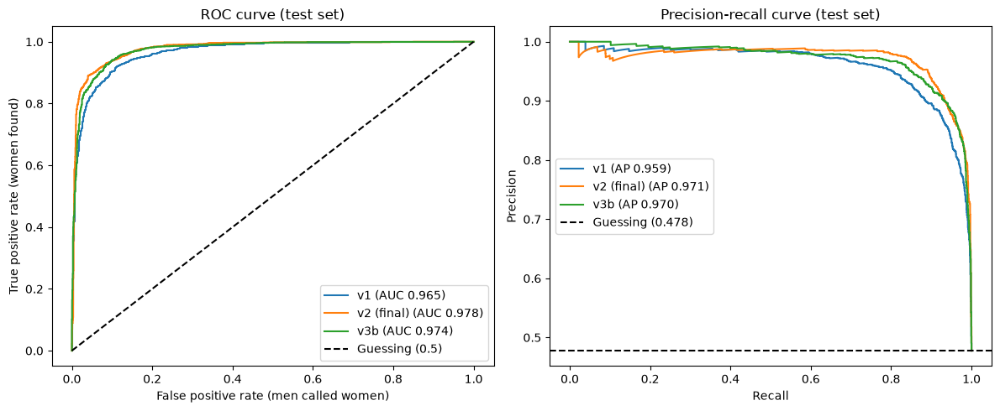

In [ ]:
# ROC and precision-recall curves for the three models on the test set. # Helped by Claude, 2026
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name, prob in [("v1", prob_t1), ("v2 (final)", prob_t2), ("v3b", prob_t3b)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, prob):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ax[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_test, prob):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="Guessing (0.5)")
ax[0].set_xlabel("False positive rate (men called women)"); ax[0].set_ylabel("True positive rate (women found)")
ax[0].set_title("ROC curve (test set)"); ax[0].legend()
ax[1].axhline(y_test.mean(), color="k", linestyle="--", label=f"Guessing ({y_test.mean():.3f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall curve (test set)"); ax[1].legend()
plt.tight_layout(); plt.show()

What this shows:

All three curves bend sharply into the top-left (ROC) and top-right (precision–recall), far from the guessing lines. v2 finds about 90% of female faces while wrongly labelling only about 5% of male faces as female. v2 and v3b almost overlap, which matches McNemar's test, and both sit above v1. An average precision of 0.971 is about twice the guessing level (0.478).

##### 6.3 Is the Final Model Fair?

Accuracy is shown for each group with a 95% confidence interval. Because the EDA (1.5) and the diagnosis (3.3) showed that age affects every group, ethnicity is also shown for ages 13+ only, so that children do not distort the
comparison.

In [ ]:
# Accuracy per group on the test set, with a 95% confidence interval (normal approximation). # Helped by Claude, 2026
d = test_meta.copy()
d["correct"]   = (pred_t2 == y_test)
d["ethnicity"] = d["ethnicity"].map(ETH_NAMES)
d["gender"]    = d["gender"].map({0: "Male", 1: "Female"})

def group_table(df, col):
    t = df.groupby(col)["correct"].agg(photos="count", accuracy="mean")
    se = np.sqrt(t["accuracy"] * (1 - t["accuracy"]) / t["photos"])       # standard error of a proportion
    t["ci_low"], t["ci_high"] = t["accuracy"] - 1.96 * se, t["accuracy"] + 1.96 * se
    return t.round(3)

print("Final model (v2) accuracy on the TEST set, with 95% confidence intervals")
for col in ["gender", "age_group", "ethnicity"]:
    print(f"\nBy {col}:"); print(group_table(d, col).to_string())
print("\nBy ethnicity, ages 13+ only:"); print(group_table(d[d["age"] >= 13], "ethnicity").to_string())

# Gender x ethnicity (the "intersectional" check from Gender Shades): adults only
print("\nAccuracy by gender AND ethnicity (ages 13+):")
print(d[d["age"] >= 13].pivot_table(index="ethnicity", columns="gender", values="correct", aggfunc="mean").round(3).to_string())

Final model (v2) accuracy on the TEST set, with 95% confidence intervals

By gender:
        photos  accuracy  ci_low  ci_high
gender                                   
Female    1668     0.923   0.910    0.936
Male      1824     0.918   0.906    0.931

By age_group:
                        photos  accuracy  ci_low  ci_high
age_group                                                
1. Baby (0-2)              263     0.620   0.561    0.678
2. Child (3-12)            247     0.798   0.747    0.848
3. Teen (13-19)            169     0.923   0.883    0.963
4. Young adult (20-39)    1760     0.964   0.955    0.972
5. Adult (40-59)           709     0.970   0.958    0.983
6. Senior (60+)            344     0.916   0.886    0.945

By ethnicity:
           photos  accuracy  ci_low  ci_high
ethnicity                                   
Asian         508     0.862   0.832    0.892
Black         667     0.936   0.917    0.954
Indian        582     0.930   0.909    0.950
Others        243     0.918 

What this shows:
- Gender: fair. Female 92.3% and male 91.8%, with overlapping confidence intervals. v1's lean towards "female" is gone.
- Age: the main weakness. Adults aged 20 - 59 score 96–97%, but babies score only 62.0% (CI 56.1 - 67.8%). In the test set 51.7% of babies are boys, so always guessing "male" would score 51.7%. The model is only about 10 points better than guessing for babies. Children score 79.8%.
- Ethnicity (all ages): Asian faces score lowest at 86.2% (CI 83.2 - 89.2%), which does not overlap White (91.8 - 94.4%). For ages 13+ only, Asian accuracy rises to 93.6%, and every group falls between 93.6% and 97.2% with overlapping intervals. As found in 3.3, most of the ethnicity gap is an age effect: Asian photos contain the most children.
- Gender × ethnicity (ages 13+): the weakest combination is Asian men (90.8%); Black women score 94.0%. This differs from the Gender Shades study, where darker-skinned women had the most errors. A likely reason is that UTKFace contains many faces from every ethnic group. Some combinations have fewer than 200 photos, so treat them with caution.

##### 6.4 What Does the Model Get Wrong?

The 24 mistakes the model was most confident about are shown. These are the most revealing errors: either the model has learned a misleading cue, or the label itself may be wrong.

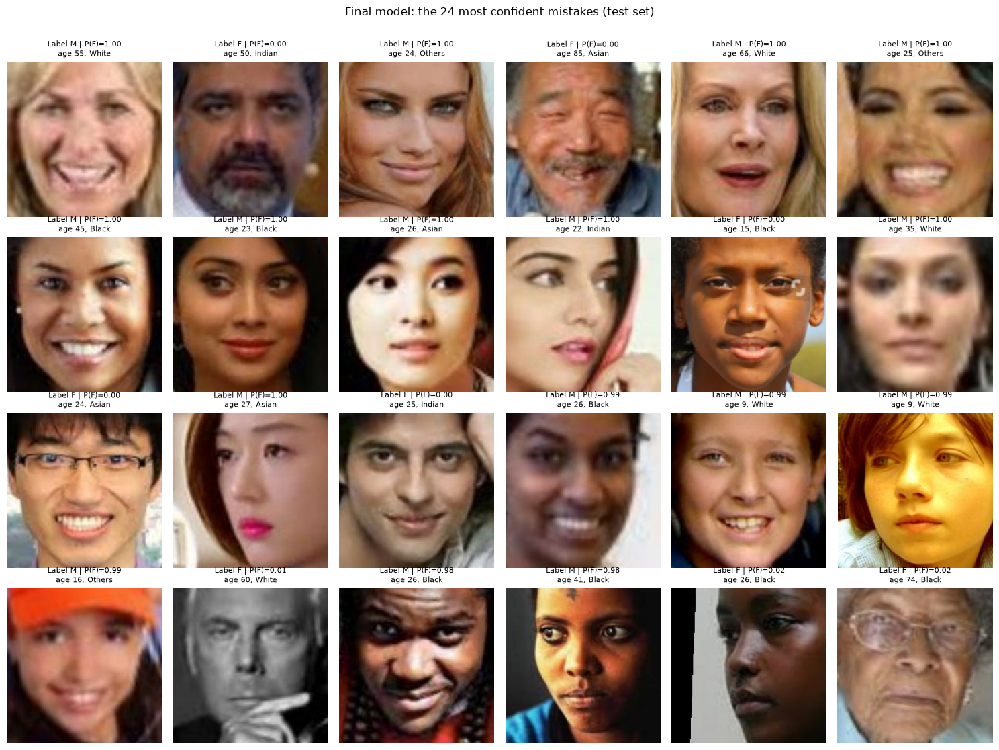

Mistakes by age group (share of all test mistakes vs share of test photos):
                        share_of_mistakes  share_of_photos
age_group                                                 
1. Baby (0-2)                       0.361            0.075
2. Child (3-12)                     0.181            0.071
3. Teen (13-19)                     0.047            0.048
4. Young adult (20-39)              0.231            0.504
5. Adult (40-59)                    0.076            0.203
6. Senior (60+)                     0.105            0.099


In [46]:
# The 24 most confident mistakes on the test set
wrong = np.where(pred_t2 != y_test)[0]
worst = wrong[np.argsort(-np.abs(prob_t2[wrong] - 0.5))][:24]       # furthest from 0.5 = most confident

fig, axes = plt.subplots(4, 6, figsize=(15, 11))
for ax, i in zip(axes.ravel(), worst):
    r = test_meta.iloc[i]
    ax.imshow(Image.open(r["path"]))
    ax.set_title(f"Label {'F' if y_test[i] else 'M'} | P(F)={prob_t2[i]:.2f}\nage {r['age']}, {ETH_NAMES[r['ethnicity']]}",
                 fontsize=8)
    ax.axis("off")
plt.suptitle("Final model: the 24 most confident mistakes (test set)", y=1.01)
plt.tight_layout(); plt.show()

print("Mistakes by age group (share of all test mistakes vs share of test photos):")
mist = test_meta.iloc[wrong]["age_group"].value_counts(normalize=True).sort_index()
share = test_meta["age_group"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"share_of_mistakes": mist, "share_of_photos": share}).round(3).to_string())

What this shows:
- Many "mistakes" are label errors. Of the 24 mistakes the model was most sure about, about 17 appear to be mislabelled photos: clearly female faces labelled "male" and clearly male faces labelled "female", for example the bearded man in row 1 and the young man with glasses in row 3. Here the model was right and the dataset was wrong. The true accuracy is therefore probably higher than 92.1%, and the label noise found in the duplicate check (1.8) is wider than the 40 photos removed there.
- The genuine errors include two 9-year-old children, a heavily shadowed side view and an elderly face with glasses: the hard cases predicted by the EDA.
- Children cause over half of all errors. Babies are 7.5% of test photos but 36.1% of mistakes, and children 7.1% of photos but 18.1% of mistakes. Under-13s are 14.6% of photos but 54.2% of all errors.

##### 6.5 Where Does the Model Look? Grad-CAM

Grad-CAM (Gradient-weighted Class Activation Mapping)colours the parts of the photo that most influenced the
decision: red = strong influence, blue = little. It uses the last convolution layer, and measures how much each feature map pushes the prediction towards the chosen answer. Because UTKFace faces are aligned, heat maps can also be averaged over many photos to show where the model looks in general.

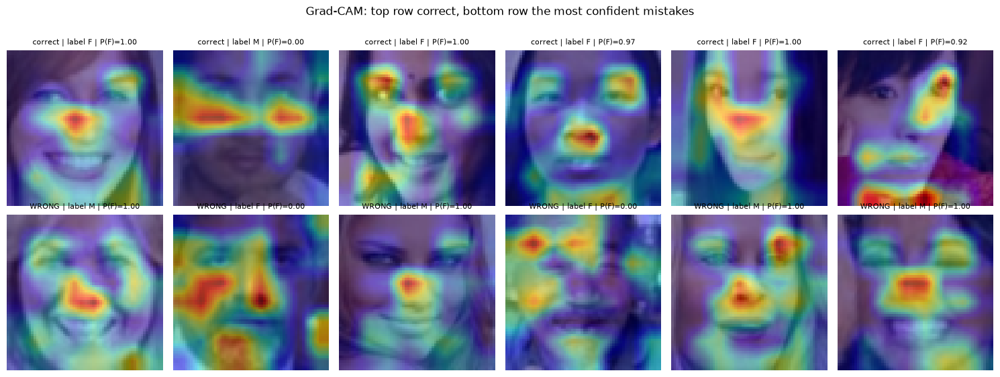

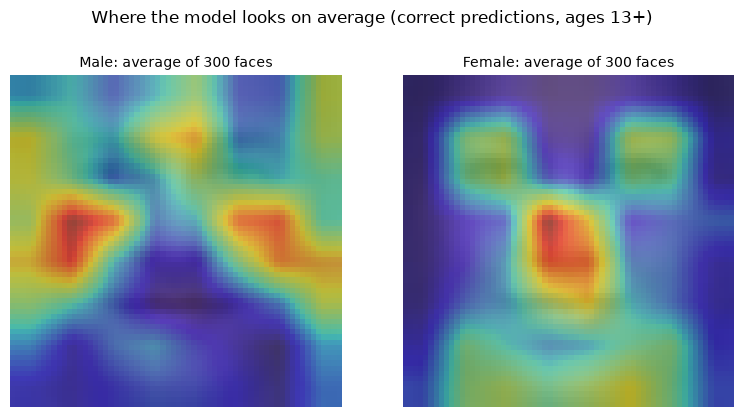

In [ ]:
# Grad-CAM for the final model (v2)  #Helped by Claude, 2026
import tensorflow as tf

# Rebuild v2 as a model with two outputs: the last convolution block's feature maps, and the prediction
last_act = [l for l in model_v2.layers if isinstance(l, layers.Activation)][-1]     # ReLU after the 4th convolution
inp = keras.Input(shape=(64, 64, 3)); x = inp
for layer in model_v2.layers:
    x = layer(x)
    if layer is last_act:
        conv_out = x
grad_model = keras.Model(inp, [conv_out, x])

def gradcam(img):
    """Heat map (64 x 64, 0-1) of the pixels that pushed the model towards its own prediction."""
    xb = tf.convert_to_tensor(img[None].astype("float32"))
    with tf.GradientTape() as tape:
        maps, pred = grad_model(xb, training=False)
        score = pred[:, 0] if float(pred[0, 0]) >= 0.5 else 1 - pred[:, 0]     # explain the predicted answer
    grads = tape.gradient(score, maps)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))                          # importance of each feature map
    cam = tf.nn.relu(tf.reduce_sum(maps[0] * weights, axis=-1))
    cam = tf.image.resize(cam[..., None], (64, 64)).numpy()[..., 0]
    return cam / (cam.max() + 1e-8), float(pred[0, 0])

# 1) Individual examples: 6 correct and 6 wrong
right = np.where(pred_t2 == y_test)[0]
examples = list(rng.choice(right, 6, replace=False)) + list(worst[:6])
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, i in zip(axes.ravel(), examples):
    cam, p = gradcam(X_test[i])
    ax.imshow(X_test[i]); ax.imshow(cam, cmap="jet", alpha=0.45)
    ok = "correct" if pred_t2[i] == y_test[i] else "WRONG"
    ax.set_title(f"{ok} | label {'F' if y_test[i] else 'M'} | P(F)={p:.2f}", fontsize=8); ax.axis("off")
plt.suptitle("Grad-CAM: top row correct, bottom row the most confident mistakes", y=1.02)
plt.tight_layout(); plt.show()

# 2) Average heat map over 300 correctly classified adult faces of each gender
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, g, name in zip(axes, [0, 1], ["Male", "Female"]):
    idx = [i for i in right if y_test[i] == g and test_meta.iloc[i]["age"] >= 13][:300]
    avg_cam = np.mean([gradcam(X_test[i])[0] for i in idx], axis=0)
    avg_face = np.mean(X_test[idx], axis=0).astype("uint8")
    ax.imshow(avg_face); ax.imshow(avg_cam, cmap="jet", alpha=0.5)
    ax.set_title(f"{name}: average of {len(idx)} faces", fontsize=10); ax.axis("off")
plt.suptitle("Where the model looks on average (correct predictions, ages 13+)", y=1.03)
plt.tight_layout(); plt.show()

What this shows:
- The model looks at the face, not the background. In correct predictions, the heat sits on the eyes, eyebrows, nose and mouth, and almost never on hair edges, clothing or background, so there is no sign of a background or clothing shortcut.
- Different clues for each gender. On average, for male faces the model focuses on the cheeks and jaw sides (where beards and stubble grow) and the brow. For female faces it focuses on the centre of the face around the eyes and nose. This matches known adult facial differences, and it explains why babies are hard: these differences have not developed yet.
- Even in its "mistakes" the model looked at sensible features. For the bearded man labelled female (bottom row, photo 2), the heat sits on the beard and cheeks and the model answered "male", which supports the view that many of these errors are label errors.

#### STEP 7: Conclusion

| Question | Answer |
|---|---|
| Final model | v2: a 4-block CNN with augmentation, batch normalisation, global average pooling and dropout |
| Test performance | 92.1% accuracy (91.2 - 92.9%), F1 0.917, ROC-AUC 0.978 |
| Improvement over baseline | +2.1 points over v1 on test (p < 0.001); v1's overfitting and lean towards "female" removed |
| Transfer learning | v3 (86.5%) underperformed. After diagnosis, v3b reached 91.6% on test, statistically equal to v2 (p = 0.33) but 5× larger and slower |
| Fairness | Equal for women and men. Ethnic groups similar for ages 13+ (93.6 - 97.2%). Much weaker for babies (62.0%) and children (79.8%) |
| Biggest limitations | Children under 13 (54% of all errors), and label noise: many confident "mistakes" are mislabelled photos |

Recommendations:
1. Do not use the model for children under 13. For babies it is right only about 6 times in 10.
2. Clean the labels. The photos the model gets wrong with high confidence are a quick way to find mislabelled images.
3. Report accuracy by group and check for hidden causes. Overall accuracy hid the baby problem, and ethnicity results without the age check would have wrongly suggested bias against Asian faces.
4. Prefer the smaller model. v2 is as accurate as the pre-trained model at a fifth of the size.
5. Future work: train on a GPU with full-size images, test on another dataset such as FairFace, and try a separate model or more photos for children.

For the publisher, the model is accurate enough for adult visitors (about 96%), but it should not be used on children, should never be the only basis for a decision about a person, and any use on the premises needs POPIA consent and clear signage, because face images are special personal information.